# Data exploration

## Network 1: Resistance game

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

import tarfile
from pathlib import Path

archivo = Path(r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\comm-f2f-Resistance-network.tar.gz")

carpeta_salida = archivo.parent / "comm-f2f-Resistance-network"

with tarfile.open(archivo, "r:gz") as tar:
    tar.extractall(path=carpeta_salida)

print("Descompresión terminada.")
print(carpeta_salida)

Descompresión terminada.
C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\comm-f2f-Resistance-network


In [5]:
import pandas as pd

ruta = carpeta_salida / "network_list.csv"

network_list = pd.read_csv(ruta)

print(network_list.head())
print(network_list)
print("Número de redes:", len(network_list))

   NETWORK  NUMBER_OF_PARTICIPANTS
0        0                       7
1        1                       8
2        2                       7
3        3                       7
4        4                       8
    NETWORK  NUMBER_OF_PARTICIPANTS
0         0                       7
1         1                       8
2         2                       7
3         3                       7
4         4                       8
..      ...                     ...
57       57                       8
58       58                       8
59       59                       7
60       60                       7
61       61                       8

[62 rows x 2 columns]
Número de redes: 62


In [6]:
ruta_network0 = carpeta_salida / "network" / "network0.csv"

network0 = pd.read_csv(ruta_network0)

print(network0.head())
print(network0.shape)

   TIME  P1_TO_LAPTOP  P1_TO_P1  P1_TO_P2  P1_TO_P3  P1_TO_P4  P1_TO_P5  \
0   0.0             1         0         0         0         0         0   
1   1.0             1         0         0         0         0         0   
2   2.0             1         0         0         0         0         0   
3   3.0             1         0         0         0         0         0   
4   4.0             1         0         0         0         0         0   

   P1_TO_P6  P1_TO_P7  P2_TO_LAPTOP  ...  P6_TO_P6  P6_TO_P7  P7_TO_LAPTOP  \
0         0         0             0  ...         0         0             0   
1         0         0             0  ...         0         0             0   
2         0         0             0  ...         0         0             0   
3         0         0             0  ...         0         0             0   
4         0         0             0  ...         0         0             0   

   P7_TO_P1  P7_TO_P2  P7_TO_P3  P7_TO_P4  P7_TO_P5  P7_TO_P6  P7_TO_P7  
0     

['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7']
Nodos: 7
Aristas: 5


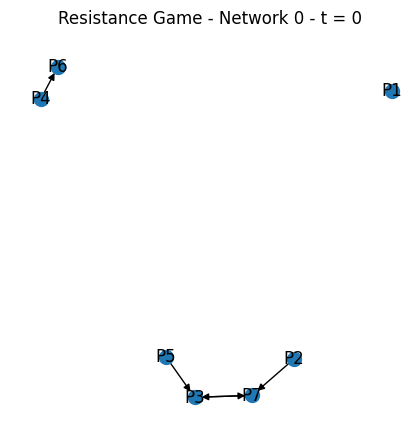

In [17]:
participantes = [
    col.split("_TO_")[0]
    for col in network0.columns
    if "_TO_" in col
]

participantes = sorted(set(participantes))

print(participantes)

G = nx.DiGraph()

G.add_nodes_from(participantes)

fila = network0.iloc[0]

for columna in network0.columns:
    
    if "_TO_" not in columna:
        continue
    
    origen, destino = columna.split("_TO_")
    
    if fila[columna] == 1:
        if destino != "LAPTOP":
            G.add_edge(origen, destino)

print("Nodos:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())

plt.figure(figsize=(4, 4))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=100,
    arrows=True
)

plt.title("Resistance Game - Network 0 - t = 0")
plt.show()

In [13]:
def construir_grafo(row):
    
    G = nx.DiGraph()
    
    for columna in row.index:
        
        if "_TO_" not in columna:
            continue
        
        origen, destino = columna.split("_TO_")
        
        if destino == "LAPTOP":
            continue
        
        if row[columna] == 1:
            G.add_edge(origen, destino)
    
    return G

for i in range(100):
    G = construir_grafo(network0.iloc[i])
    print(f"Grafo {i}: Nodos = {G.number_of_nodes()}, Aristas = {G.number_of_edges()}")


Grafo 0: Nodos = 6, Aristas = 5
Grafo 1: Nodos = 6, Aristas = 6
Grafo 2: Nodos = 6, Aristas = 6
Grafo 3: Nodos = 4, Aristas = 4
Grafo 4: Nodos = 5, Aristas = 5
Grafo 5: Nodos = 5, Aristas = 5
Grafo 6: Nodos = 6, Aristas = 6
Grafo 7: Nodos = 5, Aristas = 5
Grafo 8: Nodos = 6, Aristas = 6
Grafo 9: Nodos = 4, Aristas = 4
Grafo 10: Nodos = 5, Aristas = 5
Grafo 11: Nodos = 6, Aristas = 6
Grafo 12: Nodos = 5, Aristas = 5
Grafo 13: Nodos = 7, Aristas = 7
Grafo 14: Nodos = 7, Aristas = 7
Grafo 15: Nodos = 6, Aristas = 6
Grafo 16: Nodos = 6, Aristas = 6
Grafo 17: Nodos = 7, Aristas = 7
Grafo 18: Nodos = 6, Aristas = 6
Grafo 19: Nodos = 7, Aristas = 6
Grafo 20: Nodos = 7, Aristas = 7
Grafo 21: Nodos = 7, Aristas = 7
Grafo 22: Nodos = 7, Aristas = 7
Grafo 23: Nodos = 7, Aristas = 7
Grafo 24: Nodos = 7, Aristas = 7
Grafo 25: Nodos = 7, Aristas = 7
Grafo 26: Nodos = 7, Aristas = 7
Grafo 27: Nodos = 7, Aristas = 7
Grafo 28: Nodos = 6, Aristas = 6
Grafo 29: Nodos = 6, Aristas = 6
Grafo 30: Nodos = 7,

In [14]:
ruta_weighted = (
    carpeta_salida
    / "network"
    / "network0_weighted.csv"
)

network0_weighted = pd.read_csv(ruta_weighted)

print(network0_weighted.head())

def construir_grafo_weighted(row):
    
    G = nx.DiGraph()
    
    for columna in row.index:
        
        if "_TO_" not in columna:
            continue
        
        origen, destino = columna.split("_TO_")
        
        if destino == "LAPTOP":
            continue
        
        peso = row[columna]
        
        if peso > 0:
            G.add_edge(
                origen,
                destino,
                weight=peso
            )
    
    return G

Gw = construir_grafo_weighted(network0_weighted.iloc[0])

print(Gw.edges(data=True))

   TIME  P1_TO_LAPTOP  P1_TO_P1  P1_TO_P2  P1_TO_P3  P1_TO_P4  P1_TO_P5  \
0   0.0         0.534       0.0     0.046     0.083     0.000     0.041   
1   1.0         0.646       0.0     0.061     0.123     0.000     0.050   
2   2.0         0.730       0.0     0.043     0.088     0.006     0.041   
3   3.0         0.563       0.0     0.079     0.175     0.003     0.058   
4   4.0         0.594       0.0     0.074     0.151     0.004     0.054   

   P1_TO_P6  P1_TO_P7  P2_TO_LAPTOP  ...  P6_TO_P6  P6_TO_P7  P7_TO_LAPTOP  \
0     0.029     0.067         0.077  ...       0.0     0.120         0.094   
1     0.029     0.091         0.086  ...       0.0     0.120         0.017   
2     0.021     0.071         0.086  ...       0.0     0.141         0.031   
3     0.033     0.090         0.111  ...       0.0     0.119         0.043   
4     0.036     0.086         0.200  ...       0.0     0.110         0.043   

   P7_TO_P1  P7_TO_P2  P7_TO_P3  P7_TO_P4  P7_TO_P5  P7_TO_P6  P7_TO_P7  
0     

In [15]:
for i in range(100):
    G = construir_grafo_weighted(network0_weighted.iloc[i])
    print(f"Grafo {i}: Nodos = {G.number_of_nodes()}, Aristas = {G.number_of_edges()}")


Grafo 0: Nodos = 7, Aristas = 41
Grafo 1: Nodos = 7, Aristas = 41
Grafo 2: Nodos = 7, Aristas = 42
Grafo 3: Nodos = 7, Aristas = 42
Grafo 4: Nodos = 7, Aristas = 41
Grafo 5: Nodos = 7, Aristas = 41
Grafo 6: Nodos = 7, Aristas = 42
Grafo 7: Nodos = 7, Aristas = 41
Grafo 8: Nodos = 7, Aristas = 41
Grafo 9: Nodos = 7, Aristas = 41
Grafo 10: Nodos = 7, Aristas = 42
Grafo 11: Nodos = 7, Aristas = 40
Grafo 12: Nodos = 7, Aristas = 41
Grafo 13: Nodos = 7, Aristas = 41
Grafo 14: Nodos = 7, Aristas = 40
Grafo 15: Nodos = 7, Aristas = 41
Grafo 16: Nodos = 7, Aristas = 41
Grafo 17: Nodos = 7, Aristas = 40
Grafo 18: Nodos = 7, Aristas = 41
Grafo 19: Nodos = 7, Aristas = 38
Grafo 20: Nodos = 7, Aristas = 41
Grafo 21: Nodos = 7, Aristas = 41
Grafo 22: Nodos = 7, Aristas = 41
Grafo 23: Nodos = 7, Aristas = 41
Grafo 24: Nodos = 7, Aristas = 39
Grafo 25: Nodos = 7, Aristas = 41
Grafo 26: Nodos = 7, Aristas = 42
Grafo 27: Nodos = 7, Aristas = 42
Grafo 28: Nodos = 7, Aristas = 41
Grafo 29: Nodos = 7, Ari

## Network 2: CollegeMsg

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. CARGAR LA BASE
# ============================================================

ruta = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\CollegeMsg.txt\CollegeMsg.txt"

df = pd.read_csv(
    ruta,
    sep=r"\s+",
    header=None,
    names=["source", "target", "timestamp"]
)

print("Primeras filas:")
print(df.head())

print("\nNúmero total de mensajes:", len(df))


# ============================================================
# 2. CONVERTIR TIMESTAMP A FECHA
# ============================================================

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="s"
)

print("\nPeriodo de observación:")
print("Inicio:", df["datetime"].min())
print("Fin:", df["datetime"].max())


# ============================================================
# 3. IDENTIFICAR TODOS LOS NODOS
# ============================================================

nodos = sorted(
    set(df["source"]) | set(df["target"])
)

N = len(nodos)

print("\nNúmero total de nodos:", N)


# ============================================================
# 4. CREAR ÍNDICES NUMÉRICOS PARA LOS NODOS
# ============================================================

node_to_idx = {
    nodo: i
    for i, nodo in enumerate(nodos)
}

idx_to_node = {
    i: nodo
    for nodo, i in node_to_idx.items()
}


# ============================================================
# 5. CREAR VENTANAS DE 1 SEMANA
# ============================================================

fecha_inicio = df["datetime"].min()

df["week"] = (
    (
        df["datetime"] - fecha_inicio
    ).dt.total_seconds()
    // (7 * 24 * 60 * 60)
).astype(int)

T = df["week"].max() + 1

print("\nNúmero de semanas:", T)


# ============================================================
# 6. CONSTRUIR EL TENSOR Y
# ============================================================

Y = np.zeros(
    (N, N, T),
    dtype=int
)


for _, fila in df.iterrows():

    i = node_to_idx[fila["source"]]
    j = node_to_idx[fila["target"]]
    t = fila["week"]

    Y[i, j, t] += 1


print("\nDimensiones del tensor Y:")
print(Y.shape)

Primeras filas:
   source  target   timestamp
0       1       2  1082040961
1       3       4  1082155839
2       5       2  1082414391
3       6       7  1082439619
4       8       7  1082439756

Número total de mensajes: 59835

Periodo de observación:
Inicio: 2004-04-15 14:56:01
Fin: 2004-10-26 07:52:22

Número total de nodos: 1899

Número de semanas: 28

Dimensiones del tensor Y:
(1899, 1899, 28)


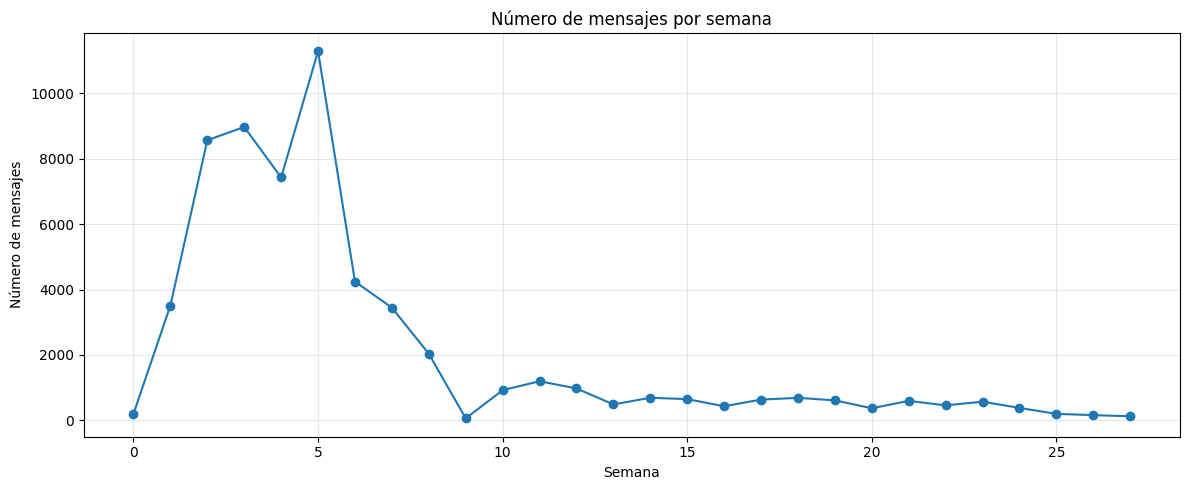

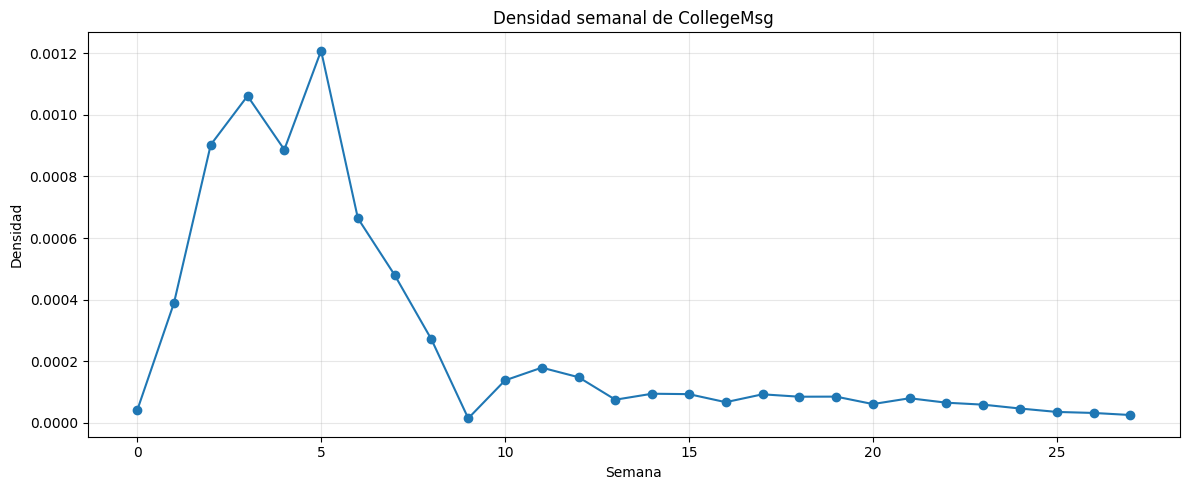

In [33]:
mensajes_por_semana = Y.sum(axis=(0, 1))
plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    mensajes_por_semana,
    marker="o"
)

plt.xlabel("Semana")
plt.ylabel("Número de mensajes")
plt.title("Número de mensajes por semana")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

A = (Y > 0).astype(int)
densidad = np.zeros(T)

for t in range(T):

    numero_aristas = A[:, :, t].sum()


    densidad[t] = (
        numero_aristas /
        (N * (N - 1))
    )

plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    densidad,
    marker="o"
)

plt.xlabel("Semana")
plt.ylabel("Densidad")
plt.title("Densidad semanal de CollegeMsg")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [71]:
np.sum(np.sum(Y, axis=(2))==0)

np.int64(3585905)

In [74]:
1899**2 - np.sum(np.sum(Y, axis=(2))==0)

np.int64(20296)

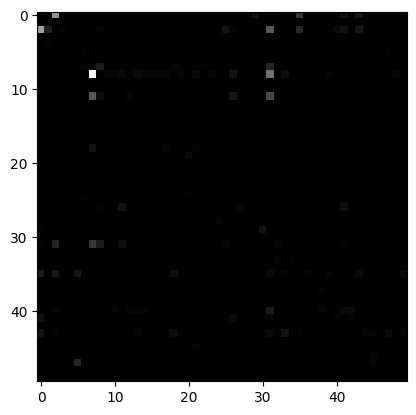

In [68]:
plt.imshow(np.sum(Y[:50,:50,:], axis=(2)), cmap="gray")
plt.show()

## Network 3: email-Eu-core

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. CARGAR LA BASE
# ============================================================

ruta = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\email-Eu-core-temporal.txt\email-Eu-core-temporal.txt"

df = pd.read_csv(
    ruta,
    sep=r"\s+",
    header=None,
    names=["source", "target", "timestamp"]
)

print("Primeras filas:")
print(df.head())

print("\nNúmero total de mensajes:", len(df))


# ============================================================
# 2. CONVERTIR TIMESTAMP A FECHA
# ============================================================

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="s"
)

print("\nPeriodo de observación:")
print("Inicio:", df["datetime"].min())
print("Fin:", df["datetime"].max())


# ============================================================
# 3. IDENTIFICAR TODOS LOS NODOS
# ============================================================

nodos = sorted(
    set(df["source"]) | set(df["target"])
)

N = len(nodos)

print("\nNúmero total de nodos:", N)


# ============================================================
# 4. CREAR ÍNDICES NUMÉRICOS PARA LOS NODOS
# ============================================================

node_to_idx = {
    nodo: i
    for i, nodo in enumerate(nodos)
}

idx_to_node = {
    i: nodo
    for nodo, i in node_to_idx.items()
}


# ============================================================
# 5. CREAR VENTANAS DE 1 SEMANA
# ============================================================

fecha_inicio = df["datetime"].min()

df["week"] = (
    (
        df["datetime"] - fecha_inicio
    ).dt.total_seconds()
    // (7 * 24 * 60 * 60)
).astype(int)

T = df["week"].max() + 1

print("\nNúmero de semanas:", T)


# ============================================================
# 6. CONSTRUIR EL TENSOR Y
# ============================================================

Y = np.zeros(
    (N, N, T),
    dtype=int
)


for _, fila in df.iterrows():

    i = node_to_idx[fila["source"]]
    j = node_to_idx[fila["target"]]
    t = fila["week"]

    Y[i, j, t] += 1


print("\nDimensiones del tensor Y:")
print(Y.shape)

Primeras filas:
   source  target  timestamp
0     582     364          0
1     168     472       2797
2     168     912       3304
3       2     790       4523
4       2     322       7926

Número total de mensajes: 332334

Periodo de observación:
Inicio: 1970-01-01 00:00:00
Fin: 1972-03-14 22:14:14

Número total de nodos: 986

Número de semanas: 115

Dimensiones del tensor Y:
(986, 986, 115)


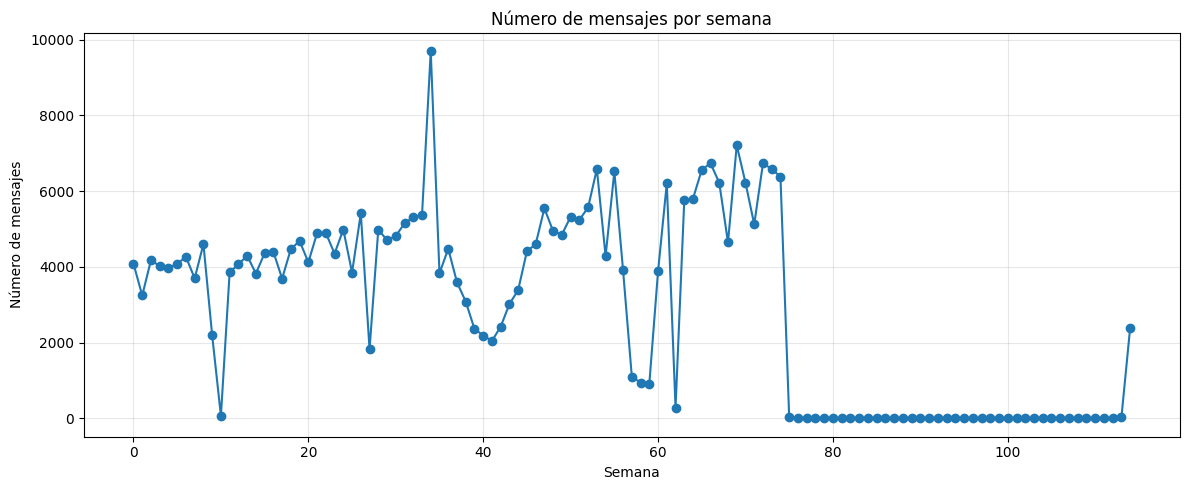

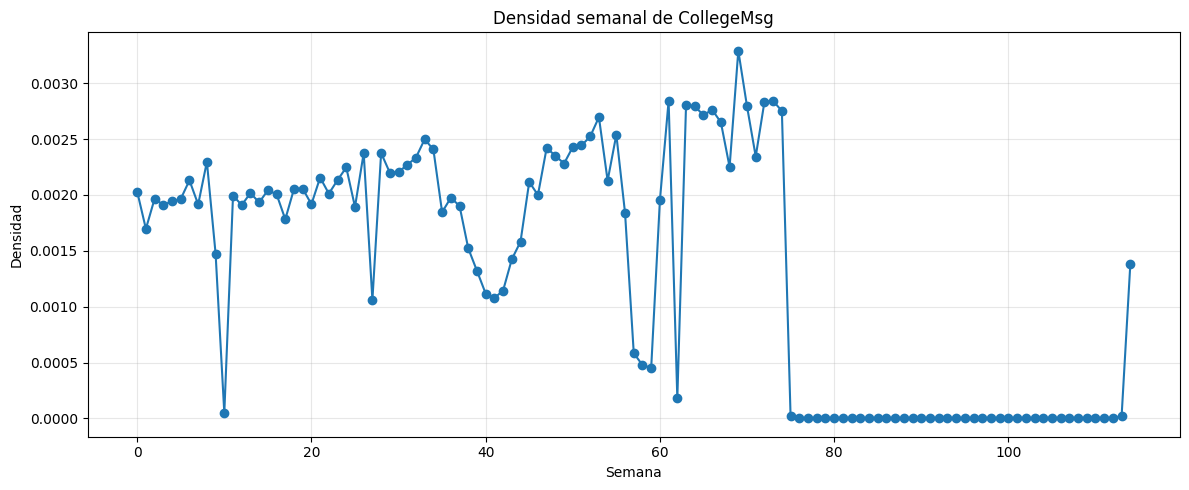

In [77]:
mensajes_por_semana = Y.sum(axis=(0, 1))
plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    mensajes_por_semana,
    marker="o"
)

plt.xlabel("Semana")
plt.ylabel("Número de mensajes")
plt.title("Número de mensajes por semana")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

A = (Y > 0).astype(int)
densidad = np.zeros(T)

for t in range(T):

    numero_aristas = A[:, :, t].sum()


    densidad[t] = (
        numero_aristas /
        (N * (N - 1))
    )

plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    densidad,
    marker="o"
)

plt.xlabel("Semana")
plt.ylabel("Densidad")
plt.title("Densidad semanal de CollegeMsg")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

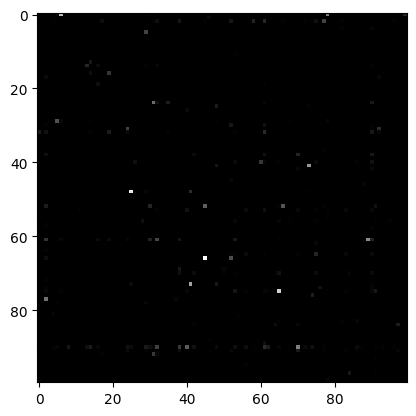

In [80]:
plt.imshow(np.sum(Y[:100,:100,:], axis=(2)), cmap="gray")
plt.show()

## Network 4: sx-mathoverflow

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# ============================================================
# 1. CARGAR LA BASE
# ============================================================

ruta = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\sx-mathoverflow.txt\sx-mathoverflow.txt"

df = pd.read_csv(
    ruta,
    sep=r"\s+",
    header=None,
    names=["source", "target", "timestamp"]
)

print("Primeras filas:")
print(df.head())

print("\nNúmero total de mensajes:", len(df))


# ============================================================
# 2. CONVERTIR TIMESTAMP A FECHA
# ============================================================

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="s"
)

print("\nPeriodo de observación:")
print("Inicio:", df["datetime"].min())
print("Fin:", df["datetime"].max())


# ============================================================
# 3. IDENTIFICAR TODOS LOS NODOS
# ============================================================

nodos = sorted(
    set(df["source"]) | set(df["target"])
)

N = len(nodos)

print("\nNúmero total de nodos:", N)


# ============================================================
# 4. CREAR ÍNDICES NUMÉRICOS PARA LOS NODOS
# ============================================================

node_to_idx = {
    nodo: i
    for i, nodo in enumerate(nodos)
}

idx_to_node = {
    i: nodo
    for nodo, i in node_to_idx.items()
}


# ============================================================
# 5. CREAR VENTANAS DE 1 SEMANA
# ============================================================

fecha_inicio = df["datetime"].min()

df["week"] = (
    (
        df["datetime"] - fecha_inicio
    ).dt.total_seconds()
    // (7 * 24 * 60 * 60)
).astype(int)

T = df["week"].max() + 1

print("\nNúmero de semanas:", T)



# ============================================================
# 6. CONSTRUIR EL TENSOR Y
# ============================================================

Y = []

for t in range(T):

    datos_semana = df[df["week"] == t]

    filas = datos_semana["source"].map(node_to_idx)
    columnas = datos_semana["target"].map(node_to_idx)

    valores = np.ones(len(datos_semana), dtype=np.int32)

    Y_t = csr_matrix(
        (
            valores,
            (filas, columnas)
        ),
        shape=(N, N)
    )

    Y_t.sum_duplicates()

    Y.append(Y_t)

Primeras filas:
   source  target   timestamp
0       1       4  1254192988
1       3       4  1254194656
2       1       2  1254202612
3      25       1  1254232804
4      14      16  1254263166

Número total de mensajes: 506550

Periodo de observación:
Inicio: 2009-09-29 02:56:28
Fin: 2016-03-06 11:05:55

Número total de nodos: 24818

Número de semanas: 336


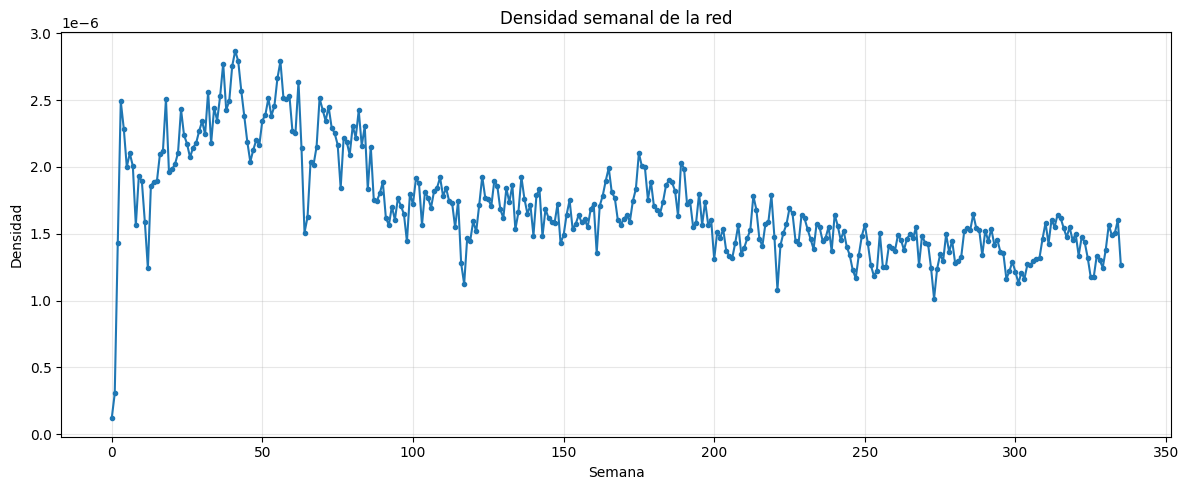

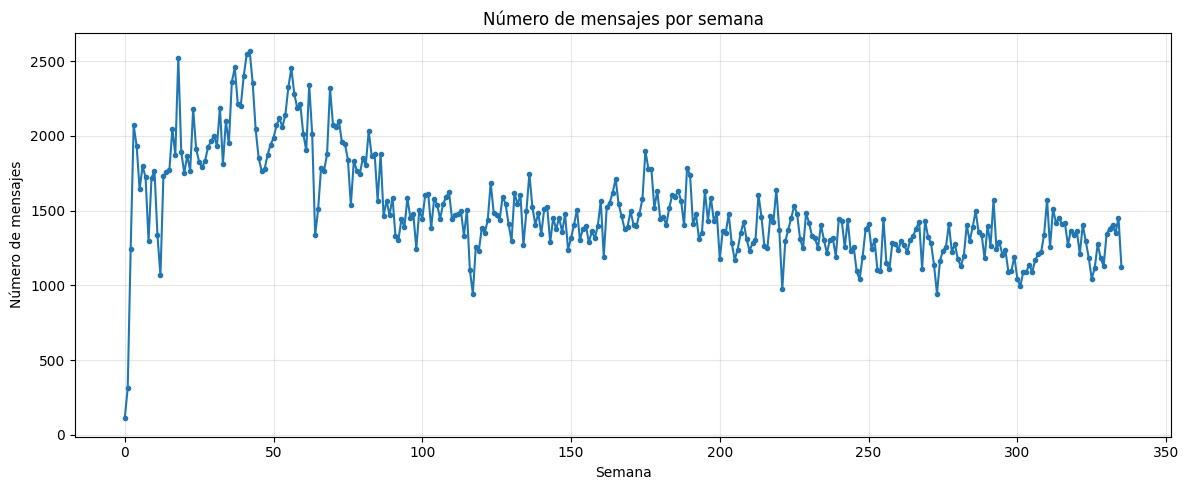

In [ ]:

densidad = []

for t in range(T):

    numero_relaciones = Y[t].nnz

    d = numero_relaciones / (N * (N - 1))

    densidad.append(d)

densidad = np.array(densidad)

plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    densidad,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Densidad")
plt.title("Densidad semanal de la red")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


mensajes_por_semana = np.array([
    Y_t.sum()
    for Y_t in Y
])

plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    mensajes_por_semana,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Número de mensajes")
plt.title("Número de mensajes por semana")

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

DIAGNÓSTICO DEL TENSOR
Número de nodos N: 24818
Número de semanas T: 336
Dimensiones conceptuales de Y:
(24818, 24818, 336)
Número total de mensajes: 506550
Primeras semanas:
[ 111  314 1245 2073 1931 1644 1798 1723 1298 1718]

Total:
506550


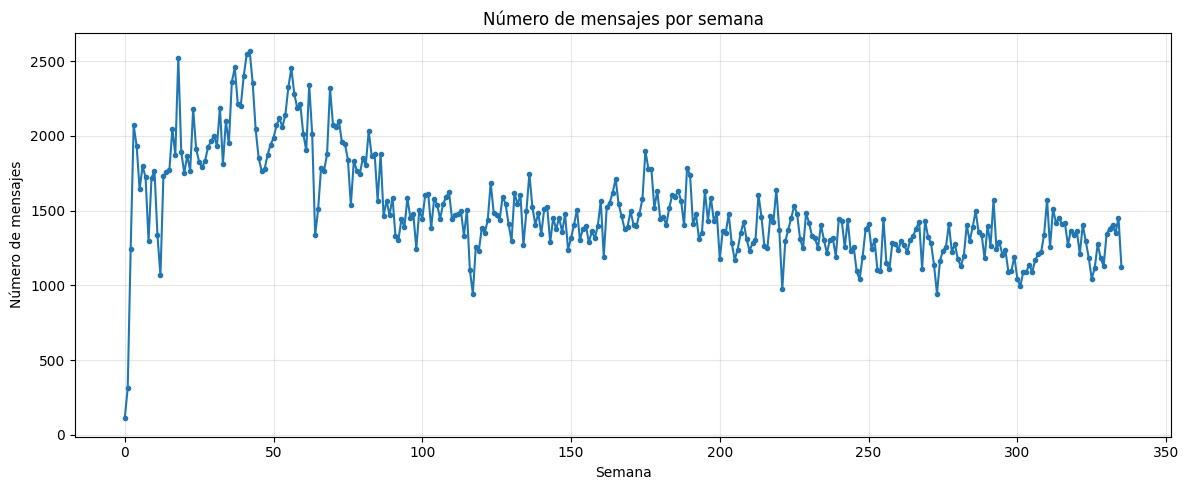

[  73  188  880 1534 1408 1232 1294 1236  962 1191]


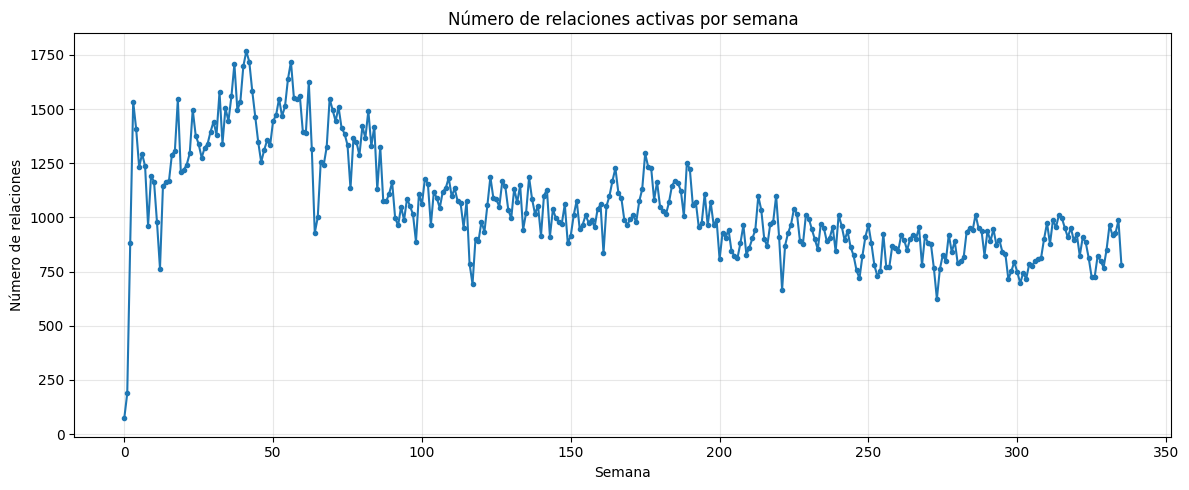

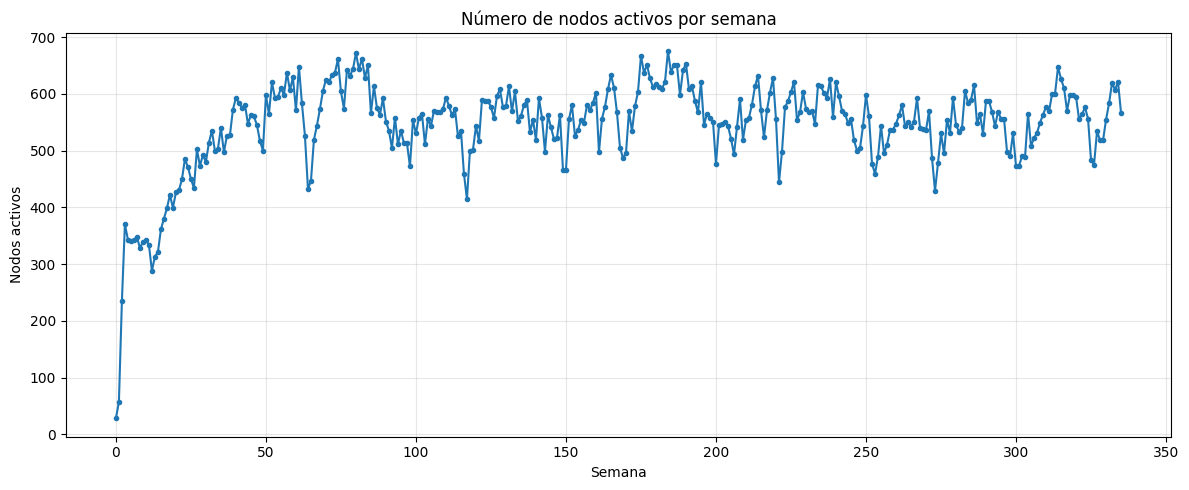

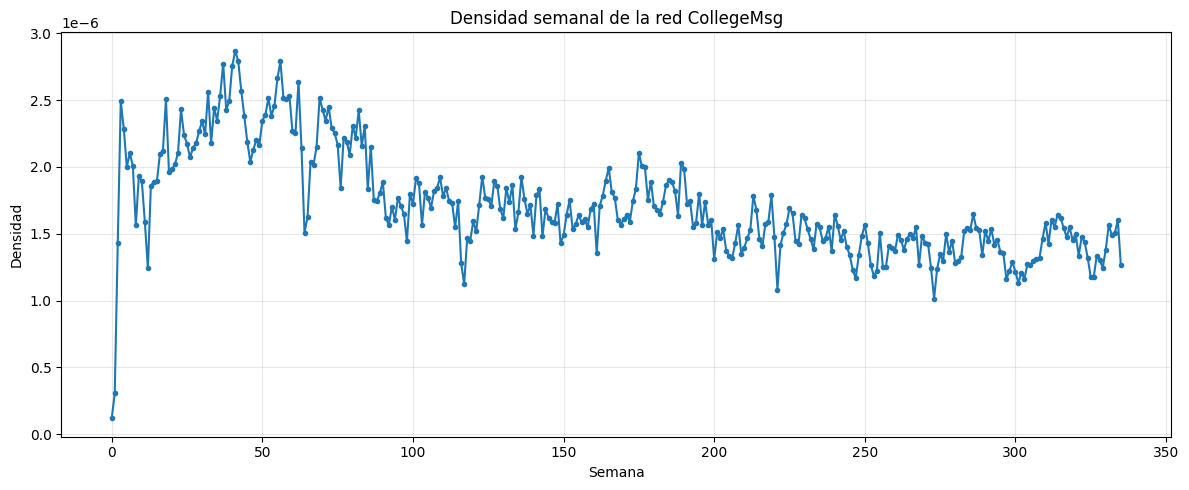

Posiciones totales: 206953529664
Posiciones no cero: 354451
Proporción de ceros: 0.9999982872918352
Porcentaje de ceros: 99.99982872918352
Número de valores positivos: 354451
Mínimo: 1
Máximo: 51
Media: 1.4291114991917078
Mediana: 1.0


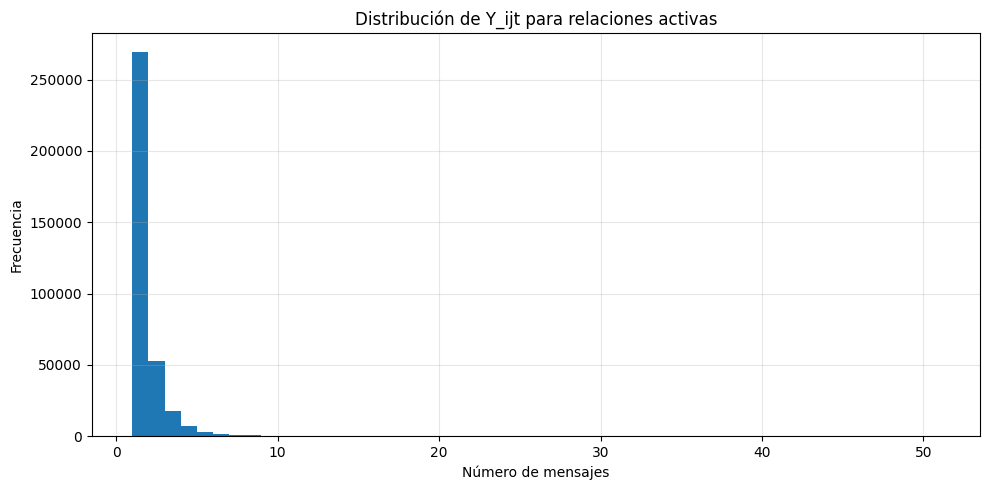

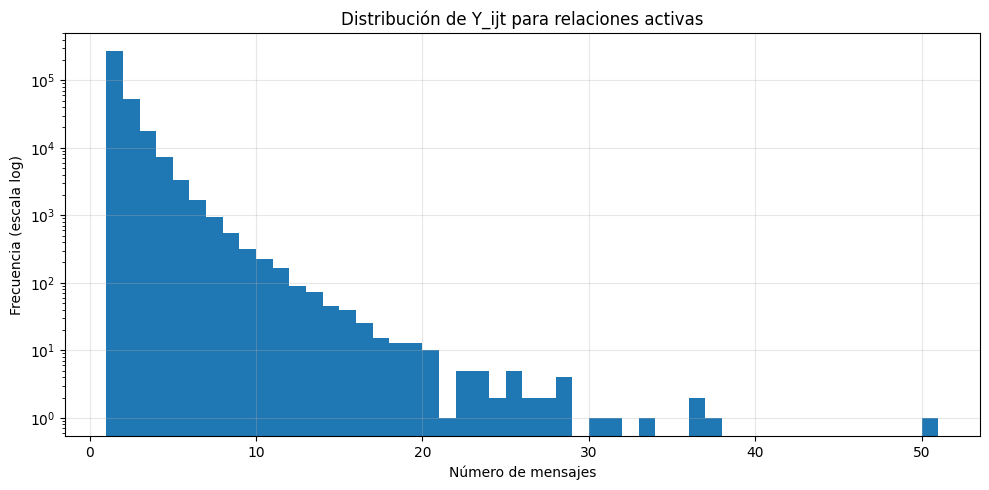

DISPERSIÓN
Media: 1.4291114991917078
Varianza: 1.17253885610265
Varianza / Media: 0.8204670221783444
MENSAJES SEMANALES
Media: 1507.5892857142858
Varianza: 111912.90274234692
Varianza / Media: 74.23301810567281
[1.         0.80256845 0.69021717 0.63884861 0.62620807 0.61357334
 0.59559322 0.58395995 0.566073   0.55908143 0.57910963 0.61325684
 0.60481862 0.57733897 0.57555067 0.55177296 0.52945937 0.50358377
 0.51558912 0.53272222 0.52608131 0.51127489 0.47996684 0.46714131
 0.48090019 0.4640607  0.4651308  0.46035033 0.42011592 0.39344415
 0.38270267]


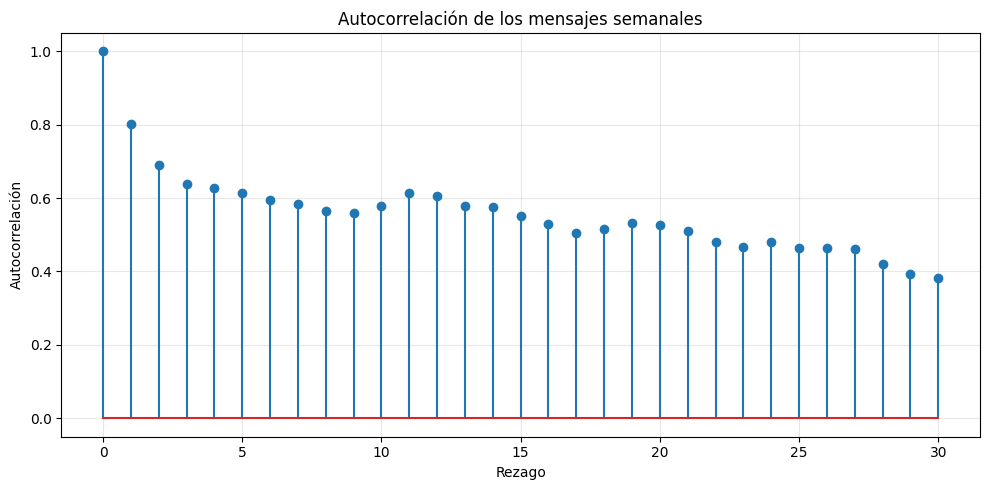

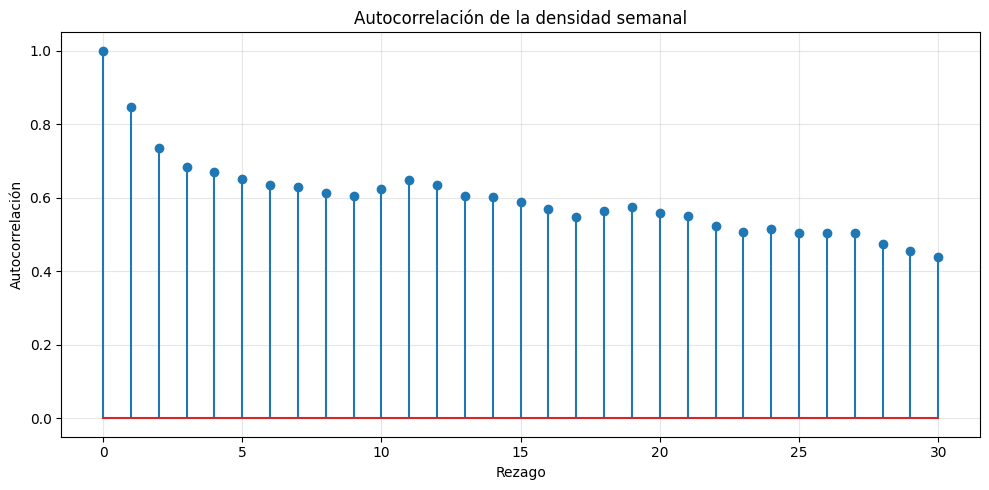

In [97]:
print("======================================")
print("DIAGNÓSTICO DEL TENSOR")
print("======================================")

print("Número de nodos N:", N)
print("Número de semanas T:", T)

print("Dimensiones conceptuales de Y:")
print(f"({N}, {N}, {T})")

print("Número total de mensajes:", int(sum(Y_t.sum() for Y_t in Y)))


mensajes_por_semana = np.array([
    Y_t.sum()
    for Y_t in Y
], dtype=np.int64)

print("Primeras semanas:")
print(mensajes_por_semana[:10])

print("\nTotal:")
print(mensajes_por_semana.sum())


plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    mensajes_por_semana,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Número de mensajes")
plt.title("Número de mensajes por semana")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

relaciones_por_semana = np.array([
    Y_t.nnz
    for Y_t in Y
], dtype=np.int64)

print(relaciones_por_semana[:10])


plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    relaciones_por_semana,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Número de relaciones")
plt.title("Número de relaciones activas por semana")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


nodos_activos = []

for Y_t in Y:

    filas_activas = Y_t.getnnz(axis=1) > 0
    columnas_activas = Y_t.getnnz(axis=0) > 0

    activos = np.logical_or(
        filas_activas,
        columnas_activas
    ).sum()

    nodos_activos.append(activos)

nodos_activos = np.array(nodos_activos)


plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    nodos_activos,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Nodos activos")
plt.title("Número de nodos activos por semana")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


densidad = np.zeros(T)

for t, Y_t in enumerate(Y):

    relaciones = Y_t.nnz

    densidad[t] = relaciones / (N * (N - 1))


plt.figure(figsize=(12, 5))

plt.plot(
    range(T),
    densidad,
    marker="o",
    markersize=3
)

plt.xlabel("Semana")
plt.ylabel("Densidad")
plt.title("Densidad semanal de la red CollegeMsg")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

total_posiciones = N * N * T

total_no_ceros = sum(
    Y_t.nnz
    for Y_t in Y
)

proporcion_ceros = (
    1 -
    total_no_ceros / total_posiciones
)

print("Posiciones totales:", total_posiciones)
print("Posiciones no cero:", total_no_ceros)
print("Proporción de ceros:", proporcion_ceros)
print("Porcentaje de ceros:", proporcion_ceros * 100)


valores_positivos = np.concatenate([
    Y_t.data
    for Y_t in Y
])

print("Número de valores positivos:", len(valores_positivos))

print("Mínimo:", valores_positivos.min())
print("Máximo:", valores_positivos.max())
print("Media:", valores_positivos.mean())
print("Mediana:", np.median(valores_positivos))


plt.figure(figsize=(10, 5))

plt.hist(
    valores_positivos,
    bins=50
)

plt.xlabel("Número de mensajes")
plt.ylabel("Frecuencia")
plt.title(
    "Distribución de Y_ijt para relaciones activas"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.hist(
    valores_positivos,
    bins=50,
    log=True
)

plt.xlabel("Número de mensajes")
plt.ylabel("Frecuencia (escala log)")
plt.title(
    "Distribución de Y_ijt para relaciones activas"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


media_Y = valores_positivos.mean()
varianza_Y = valores_positivos.var()

indice_dispersion = varianza_Y / media_Y

print("======================================")
print("DISPERSIÓN")
print("======================================")

print("Media:", media_Y)
print("Varianza:", varianza_Y)
print("Varianza / Media:", indice_dispersion)


media_M = mensajes_por_semana.mean()
varianza_M = mensajes_por_semana.var()

print("======================================")
print("MENSAJES SEMANALES")
print("======================================")

print("Media:", media_M)
print("Varianza:", varianza_M)
print("Varianza / Media:", varianza_M / media_M)

from statsmodels.tsa.stattools import acf


acf_mensajes = acf(
    mensajes_por_semana,
    nlags=30,
    fft=True
)

print(acf_mensajes)


plt.figure(figsize=(10, 5))

plt.stem(
    range(len(acf_mensajes)),
    acf_mensajes
)

plt.xlabel("Rezago")
plt.ylabel("Autocorrelación")
plt.title(
    "Autocorrelación de los mensajes semanales"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


acf_densidad = acf(
    densidad,
    nlags=30,
    fft=True
)


plt.figure(figsize=(10, 5))

plt.stem(
    range(len(acf_densidad)),
    acf_densidad
)

plt.xlabel("Rezago")
plt.ylabel("Autocorrelación")
plt.title(
    "Autocorrelación de la densidad semanal"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Network 5: cit-HepPh

In [12]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


# ============================================================
# 1. RUTAS
# ============================================================

ruta_edges = (
    r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\cit-HepPh.txt\cit-HepPh.txt"
)

ruta_dates = (
    r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\cit-HepPh.txt\cit-HepPh-dates.txt"
)


# ============================================================
# 2. CARGAR CITACIONES
# ============================================================

edges = pd.read_csv(
    ruta_edges,
    sep=r"\s+",
    comment="#",
    header=None,
    names=["source", "target"]
)


# ============================================================
# 3. CARGAR FECHAS
# ============================================================

dates = pd.read_csv(
    ruta_dates,
    sep=r"\s+",
    comment="#",
    header=None,
    names=["node", "date"]
)

dates["date"] = pd.to_datetime(
    dates["date"],
    errors="coerce"
)


# ============================================================
# 4. NODOS REALES DE LA RED
# ============================================================

nodos = sorted(
    set(edges["source"]) |
    set(edges["target"])
)

N = len(nodos)

print("Número de nodos de la red:", N)
print("Número de aristas:", len(edges))

Número de nodos de la red: 34546
Número de aristas: 421578


In [17]:
fecha_nodo = dict(
    zip(
        dates["node"],
        dates["date"]
    )
)

print(fecha_nodo.get(9907233))
print(fecha_nodo.get(9301253))

nodos_sin_fecha = [
    nodo
    for nodo in nodos
    if nodo not in fecha_nodo
]

print(
    "Nodos de la red sin fecha:",
    len(nodos_sin_fecha)
)

print(
    "Primeros nodos sin fecha:",
    nodos_sin_fecha[:20]
)

edges["source_date"] = edges["source"].map(
    fecha_nodo
)

print(
    "Aristas con fecha:",
    edges["source_date"].notna().sum()
)

print(
    "Aristas sin fecha:",
    edges["source_date"].isna().sum()
)

edges_temporales = edges[
    edges["source_date"].notna()
].copy()

print(
    "Aristas utilizadas temporalmente:",
    len(edges_temporales)
)

edges_temporales["month"] = (
    edges_temporales["source_date"]
    .dt.to_period("M")
)

months = pd.period_range(
    start=edges_temporales["month"].min(),
    end=edges_temporales["month"].max(),
    freq="M"
)

T = len(months)

print("Número de meses:", T)
print("Primer mes:", months[0])
print("Último mes:", months[-1])

1999-07-05 00:00:00
1993-01-21 00:00:00
Nodos de la red sin fecha: 3988
Primeros nodos sin fecha: [203110, 203111, 203112, 203113, 203114, 203115, 203117, 203118, 203119, 203120, 203121, 203122, 203123, 203124, 203125, 203126, 203127, 203128, 203129, 203130]
Aristas con fecha: 347414
Aristas sin fecha: 74164
Aristas utilizadas temporalmente: 347414
Número de meses: 121
Primer mes: 1992-03
Último mes: 2002-03


In [18]:
redes = {}

G_acum = nx.DiGraph()

# TODOS los nodos de la red
G_acum.add_nodes_from(nodos)


for month in months:

    datos_mes = edges_temporales[
        edges_temporales["month"] == month
    ]

    # Nuevas citaciones de este mes
    G_acum.add_edges_from(
        datos_mes[
            ["source", "target"]
        ].itertuples(
            index=False,
            name=None
        )
    )

    # Guardar una copia
    redes[month] = G_acum.copy()

     month  nodes  edges       density
0  1992-03  34546      3  2.513844e-09
1  1992-04  34546      4  3.351792e-09
2  1992-05  34546      7  5.865636e-09
3  1992-06  34546     12  1.005538e-08
4  1992-07  34546     25  2.094870e-08


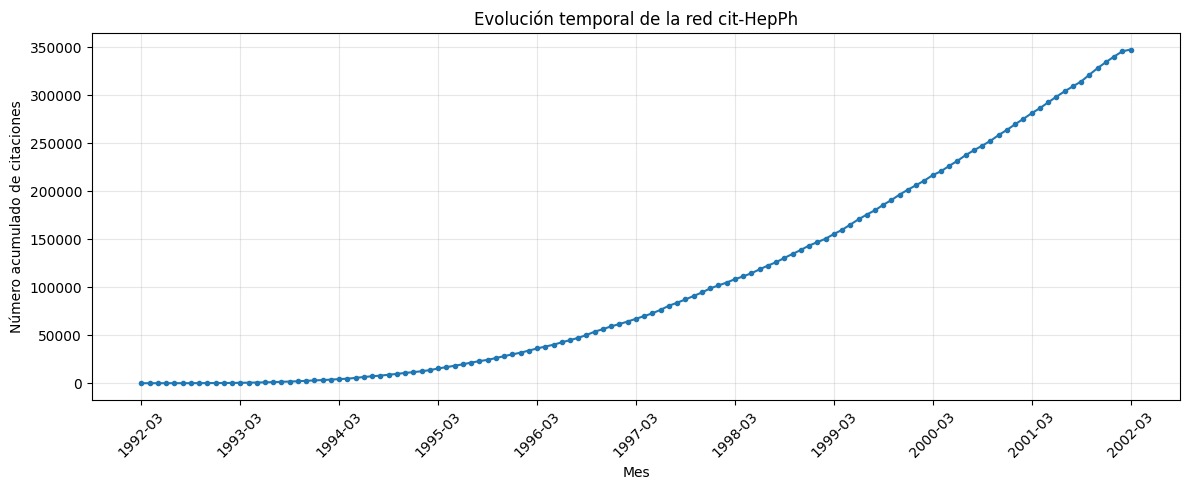

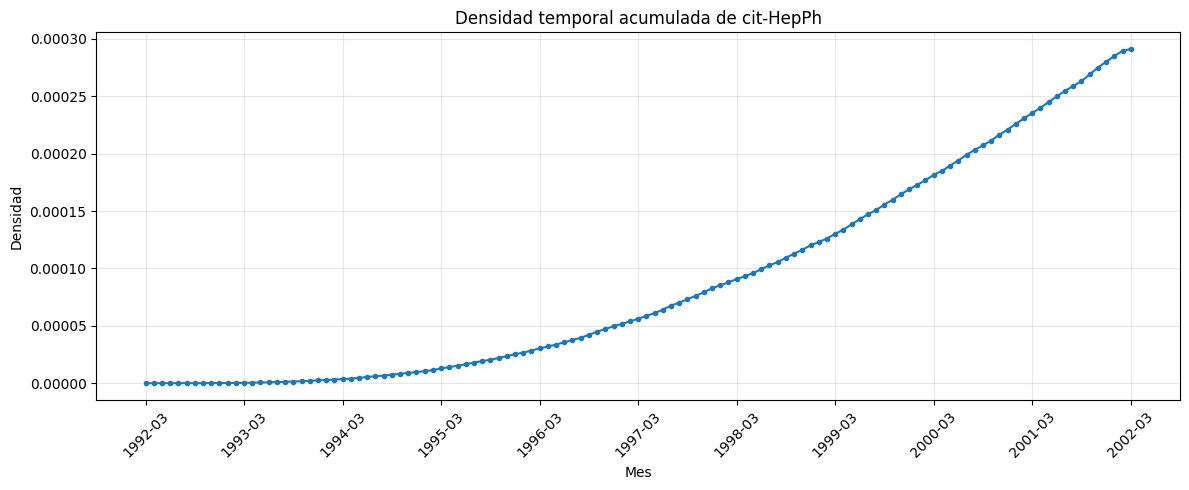

In [20]:
numero_nodos = []
numero_aristas = []
densidad = []

for month in months:

    G_t = redes[month]

    numero_nodos.append(
        G_t.number_of_nodes()
    )

    numero_aristas.append(
        G_t.number_of_edges()
    )

    densidad.append(
        nx.density(G_t)
    )

diagnostico = pd.DataFrame({
    "month": months.astype(str),
    "nodes": numero_nodos,
    "edges": numero_aristas,
    "density": densidad
})

print(diagnostico.head())

plt.figure(figsize=(12, 5))

plt.plot(
    diagnostico["month"],
    diagnostico["edges"],
    marker="o",
    markersize=3
)

plt.xlabel("Mes")
plt.ylabel("Número acumulado de citaciones")
plt.title(
    "Evolución temporal de la red cit-HepPh"
)

plt.xticks(
    range(0, T, 12),
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

plt.plot(
    diagnostico["month"],
    diagnostico["density"],
    marker="o",
    markersize=3
)

plt.xlabel("Mes")
plt.ylabel("Densidad")
plt.title(
    "Densidad temporal acumulada de cit-HepPh"
)

plt.xticks(
    range(0, T, 12),
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Network 6: hypertext-conf

In [23]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


# ============================================================
# 1. RUTA
# ============================================================

ruta = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\hypertext-conf.txt"


# ============================================================
# 2. CARGAR DATOS
# ============================================================

df = pd.read_csv(
    ruta,
    sep=r"\s+",
    header=None,
    names=["source", "target", "time"]
)


print("Primeras filas:")
print(df.head())

print("\nNúmero de contactos registrados:")
print(len(df))

nodos = sorted(
    set(df["source"]) |
    set(df["target"])
)

N = len(nodos)

print("Número de nodos:", N)


tiempos = sorted(
    df["time"].unique()
)

T = len(tiempos)

print("Número de instantes:", T)

print("Primeros tiempos:")
print(tiempos[:20])

print("Últimos tiempos:")
print(tiempos[-20:])

Primeras filas:
   source  target  time
0    1336    1337    20
1    1336    1337    40
2    1336    1337    60
3    1336    1337    80
4    1336    1337   100

Número de contactos registrados:
20818
Número de nodos: 113
Número de instantes: 5246
Primeros tiempos:
[np.int64(20), np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160), np.int64(180), np.int64(200), np.int64(220), np.int64(240), np.int64(260), np.int64(280), np.int64(300), np.int64(320), np.int64(340), np.int64(360), np.int64(380), np.int64(400)]
Últimos tiempos:
[np.int64(211920), np.int64(211960), np.int64(211980), np.int64(212000), np.int64(212020), np.int64(212040), np.int64(212060), np.int64(212080), np.int64(212100), np.int64(212120), np.int64(212140), np.int64(212160), np.int64(212180), np.int64(212200), np.int64(212240), np.int64(212260), np.int64(212280), np.int64(212320), np.int64(212340), np.int64(212360)]


In [24]:
redes = {}

for t in tiempos:

    G_t = nx.Graph()

    # TODOS los nodos
    G_t.add_nodes_from(nodos)

    # Contactos en ese instante
    datos_t = df[
        df["time"] == t
    ]

    # Agregar contactos
    G_t.add_edges_from(
        datos_t[
            ["source", "target"]
        ].itertuples(
            index=False,
            name=None
        )
    )

    redes[t] = G_t

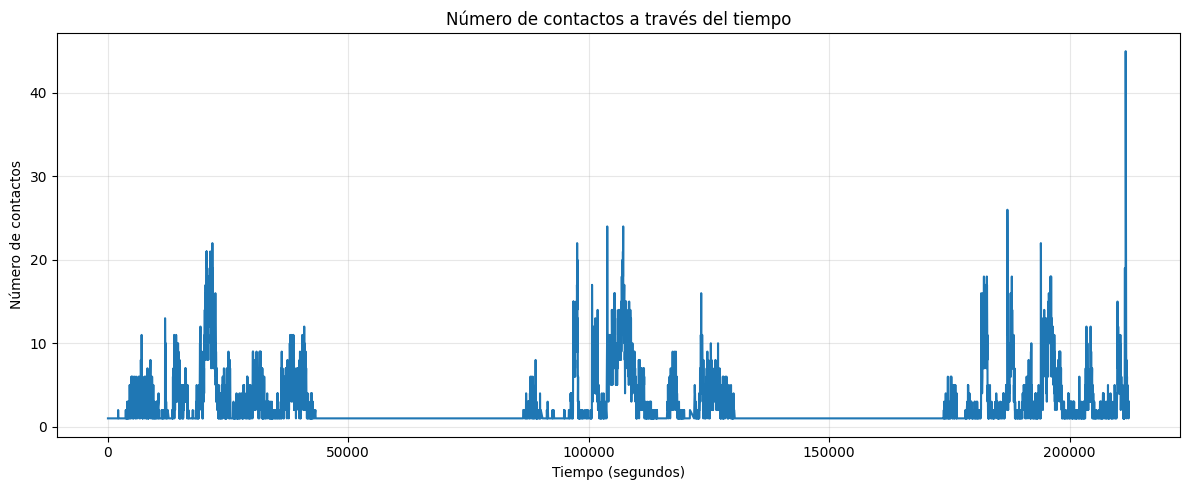

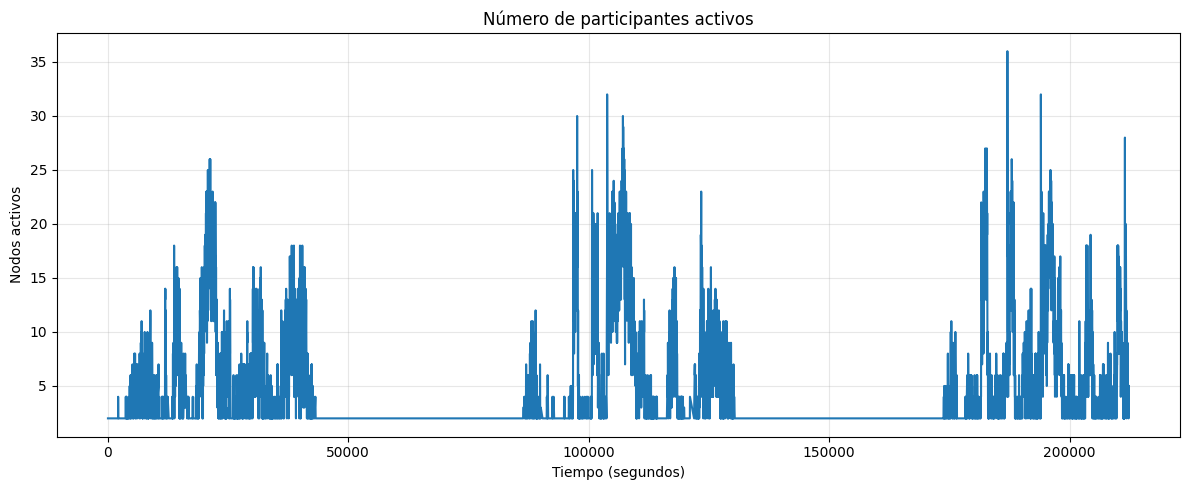

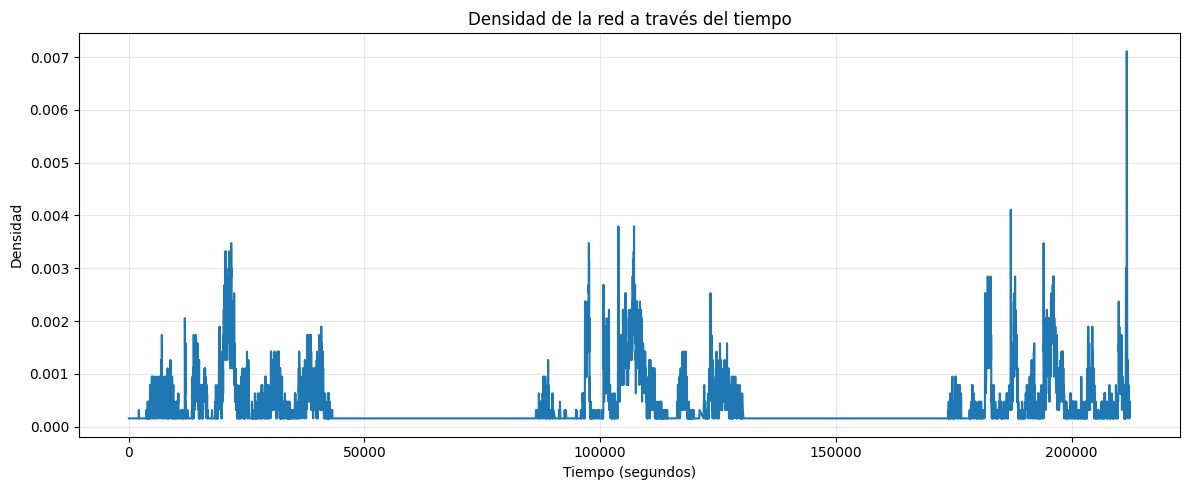

In [29]:
numero_contactos = np.array([
    redes[t].number_of_edges()
    for t in tiempos
])
plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    numero_contactos
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Número de contactos")
plt.title(
    "Número de contactos a través del tiempo"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


nodos_activos = np.array([
    sum(
        grado > 0
        for _, grado in redes[t].degree()
    )
    for t in tiempos
])

plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    nodos_activos
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Nodos activos")
plt.title(
    "Número de participantes activos"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


densidad = np.array([
    nx.density(redes[t])
    for t in tiempos
])

plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    densidad
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Densidad")
plt.title(
    "Densidad de la red a través del tiempo"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
node_to_idx = {
    nodo: i
    for i, nodo in enumerate(nodos)
}

time_to_idx = {
    t: k
    for k, t in enumerate(tiempos)
}

A = np.zeros(
    (N, N, T),
    dtype=np.int8
)

for _, fila in df.iterrows():

    i = node_to_idx[fila["source"]]
    j = node_to_idx[fila["target"]]
    t = time_to_idx[fila["time"]]

    A[i, j, t] = 1
    A[j, i, t] = 1

print("Dimensiones de A:")
print(A.shape)

print(
    "¿El tensor es simétrico?",
    np.array_equal(
        A,
        A.transpose(1, 0, 2)
    )
)

Dimensiones de A:
(113, 113, 5246)
¿El tensor es simétrico? True


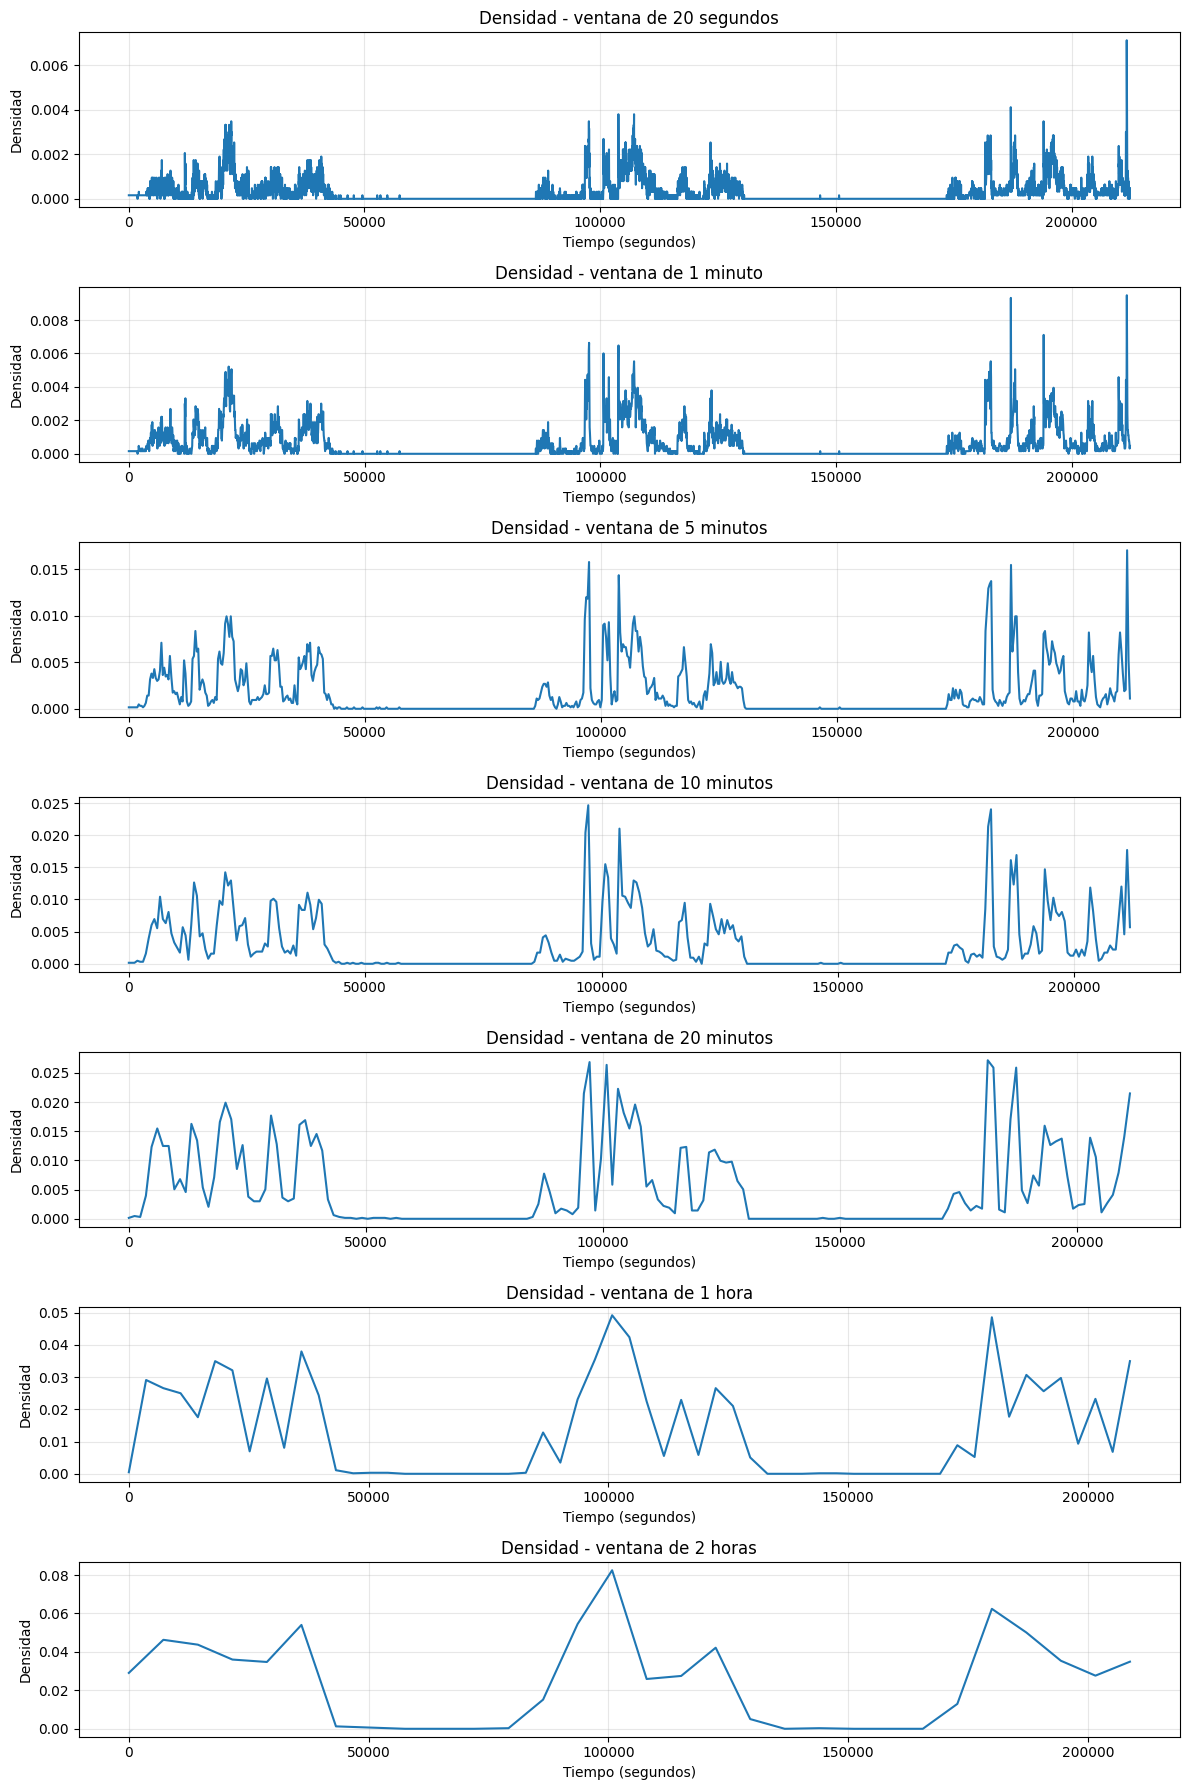

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURACIÓN
# ============================================================

N = len(nodos)

# Ventanas temporales en segundos
ventanas = {
    "20 segundos": 20,
    "1 minuto": 60,
    "5 minutos": 5 * 60,
    "10 minutos": 10 * 60,
    "20 minutos": 20 * 60,
    "1 hora": 60 * 60,
    "2 horas": 2 * 60 * 60,
}


# ============================================================
# FUNCIÓN PARA AGREGAR TEMPORALMENTE
# ============================================================

def analizar_ventana(df, ventana, N):

    datos = df.copy()

    # Asignar cada contacto a una ventana temporal
    datos["time_window"] = (
        datos["time"] // ventana
    ).astype(int)

    # Número de relaciones diferentes por ventana
    relaciones = (
        datos
        .groupby("time_window")
        .size()
    )

    # Eliminar duplicados i-j dentro de cada ventana
    relaciones_unicas = (
        datos[
            ["source", "target", "time_window"]
        ]
        .drop_duplicates()
        .groupby("time_window")
        .size()
    )

    # Nodos activos
    nodos_activos = (
        datos
        .groupby("time_window")
        .apply(
            lambda x: len(
                set(x["source"]) |
                set(x["target"])
            )
        )
    )

    # Todos los intervalos existentes
    t_min = datos["time_window"].min()
    t_max = datos["time_window"].max()

    ventanas_completas = np.arange(
        t_min,
        t_max + 1
    )

    # Rellenar ventanas sin contactos con cero
    relaciones_unicas = (
        relaciones_unicas
        .reindex(
            ventanas_completas,
            fill_value=0
        )
    )

    nodos_activos = (
        nodos_activos
        .reindex(
            ventanas_completas,
            fill_value=0
        )
    )

    # Densidad
    densidad = (
        relaciones_unicas /
        (N * (N - 1) / 2)
    )

    return {
        "ventanas": ventanas_completas,
        "relaciones": relaciones_unicas,
        "nodos_activos": nodos_activos,
        "densidad": densidad
    }

resultados = {}

for nombre, ventana in ventanas.items():

    resultados[nombre] = analizar_ventana(
        df,
        ventana,
        N
    )


fig, axes = plt.subplots(
    len(ventanas),
    1,
    figsize=(12, 18)
)

for ax, (nombre, resultado) in zip(
    axes,
    resultados.items()
):

    ax.plot(
        resultado["ventanas"] * ventanas[nombre],
        resultado["densidad"]
    )

    ax.set_title(
        f"Densidad - ventana de {nombre}"
    )

    ax.set_xlabel("Tiempo (segundos)")
    ax.set_ylabel("Densidad")

    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [50]:
resumen = []

for nombre, resultado in resultados.items():

    d = resultado["densidad"]
    activos = resultado["nodos_activos"]
    relaciones = resultado["relaciones"]

    resumen.append({
        "ventana": nombre,
        "segundos": ventanas[nombre],
        "snapshots": len(resultado["ventanas"]),
        "densidad_media": d.mean(),
        "densidad_mediana": d.median(),
        "densidad_max": d.max(),
        "nodos_activos_promedio": activos.mean(),
        "relaciones_promedio": relaciones.mean(),
        "snapshots_sin_aristas": (relaciones == 0).sum(),
        "porcentaje_snapshots_vacios":
            100 * (relaciones == 0).mean()
    })

resumen_df = pd.DataFrame(resumen)

display(resumen_df)

,ventana,segundos,snapshots,densidad_media,densidad_mediana,densidad_max,nodos_activos_promedio,relaciones_promedio,snapshots_sin_aristas,porcentaje_snapshots_vacios
0,20 segundos,20,10618,0.000310,0.000000,0.007111,3.299303,1.960633,5372,50.593332
1,1 minuto,60,3540,0.000600,0.000158,0.009482,5.566384,3.796893,1585,44.774011
2,5 minutos,300,708,0.001765,0.000474,0.017067,12.011299,11.168079,275,38.841808
3,10 minutos,600,354,0.002985,0.001106,0.024652,16.644068,18.887006,131,37.005650
4,20 minutos,1200,177,0.005256,0.001738,0.027181,23.457627,33.259887,59,33.333333
5,1 hora,3600,59,0.013408,0.006795,0.049147,38.355932,84.847458,16,27.118644
6,2 horas,7200,30,0.024094,0.026707,0.082491,48.266667,152.466667,7,23.333333


## Network 7: primary-school

In [51]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


# ============================================================
# 1. RUTA
# ============================================================

ruta = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\primary-school.txt"


# ============================================================
# 2. CARGAR DATOS
# ============================================================

df = pd.read_csv(
    ruta,
    sep=r"\s+",
    header=None,
    names=["source", "target", "time"]
)


print("Primeras filas:")
print(df.head())

print("\nNúmero de contactos registrados:")
print(len(df))

nodos = sorted(
    set(df["source"]) |
    set(df["target"])
)

N = len(nodos)

print("Número de nodos:", N)


tiempos = sorted(
    df["time"].unique()
)

T = len(tiempos)

print("Número de instantes:", T)

print("Primeros tiempos:")
print(tiempos[:20])

print("Últimos tiempos:")
print(tiempos[-20:])

Primeras filas:
   source  target   time
0    1558    1567  31220
1    1560    1570  31220
2    1567    1574  31220
3    1632    1818  31220
4    1632    1866  31220

Número de contactos registrados:
125773
Número de nodos: 242
Número de instantes: 3100
Primeros tiempos:
[np.int64(31220), np.int64(31240), np.int64(31260), np.int64(31280), np.int64(31300), np.int64(31320), np.int64(31340), np.int64(31360), np.int64(31380), np.int64(31400), np.int64(31420), np.int64(31440), np.int64(31460), np.int64(31480), np.int64(31500), np.int64(31520), np.int64(31540), np.int64(31560), np.int64(31580), np.int64(31600)]
Últimos tiempos:
[np.int64(147740), np.int64(147760), np.int64(147780), np.int64(147800), np.int64(147820), np.int64(147840), np.int64(147860), np.int64(147880), np.int64(147900), np.int64(147920), np.int64(147940), np.int64(147960), np.int64(147980), np.int64(148000), np.int64(148020), np.int64(148040), np.int64(148060), np.int64(148080), np.int64(148100), np.int64(148120)]


In [52]:
redes = {}

for t in tiempos:

    G_t = nx.Graph()

    # TODOS los nodos
    G_t.add_nodes_from(nodos)

    # Contactos en ese instante
    datos_t = df[
        df["time"] == t
    ]

    # Agregar contactos
    G_t.add_edges_from(
        datos_t[
            ["source", "target"]
        ].itertuples(
            index=False,
            name=None
        )
    )

    redes[t] = G_t

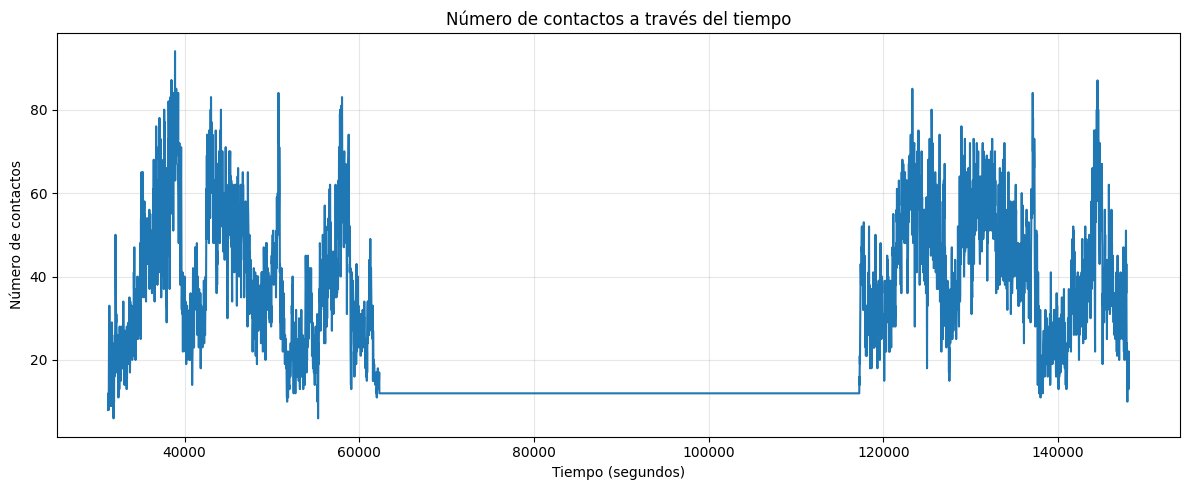

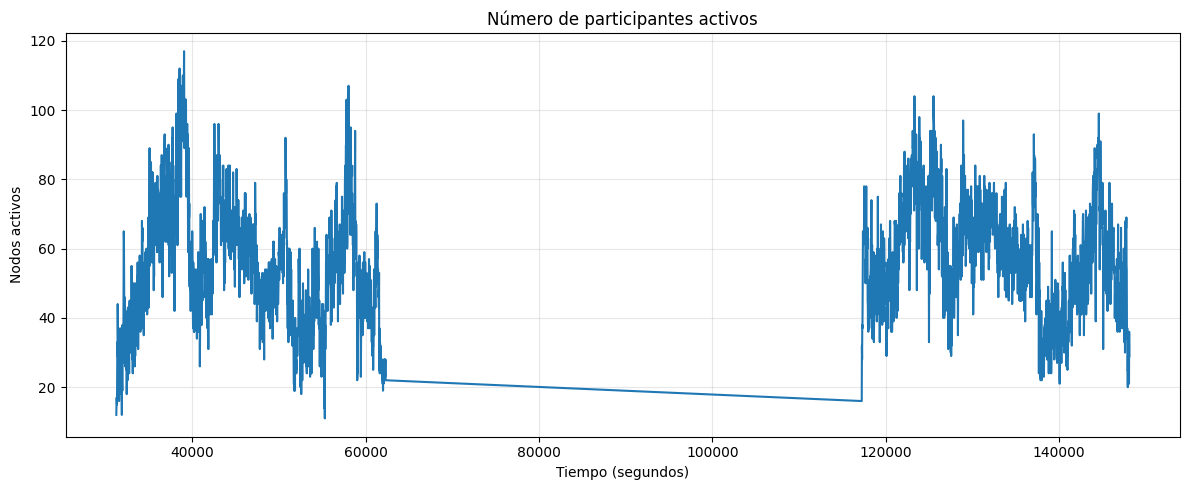

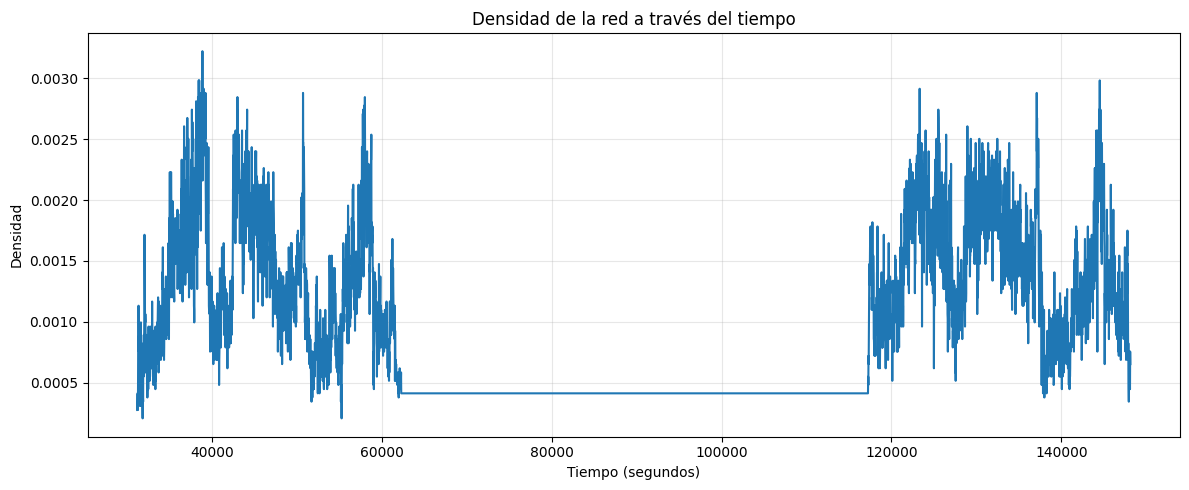

In [53]:
numero_contactos = np.array([
    redes[t].number_of_edges()
    for t in tiempos
])
plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    numero_contactos
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Número de contactos")
plt.title(
    "Número de contactos a través del tiempo"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


nodos_activos = np.array([
    sum(
        grado > 0
        for _, grado in redes[t].degree()
    )
    for t in tiempos
])

plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    nodos_activos
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Nodos activos")
plt.title(
    "Número de participantes activos"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


densidad = np.array([
    nx.density(redes[t])
    for t in tiempos
])

plt.figure(figsize=(12, 5))

plt.plot(
    tiempos,
    densidad
)

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Densidad")
plt.title(
    "Densidad de la red a través del tiempo"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

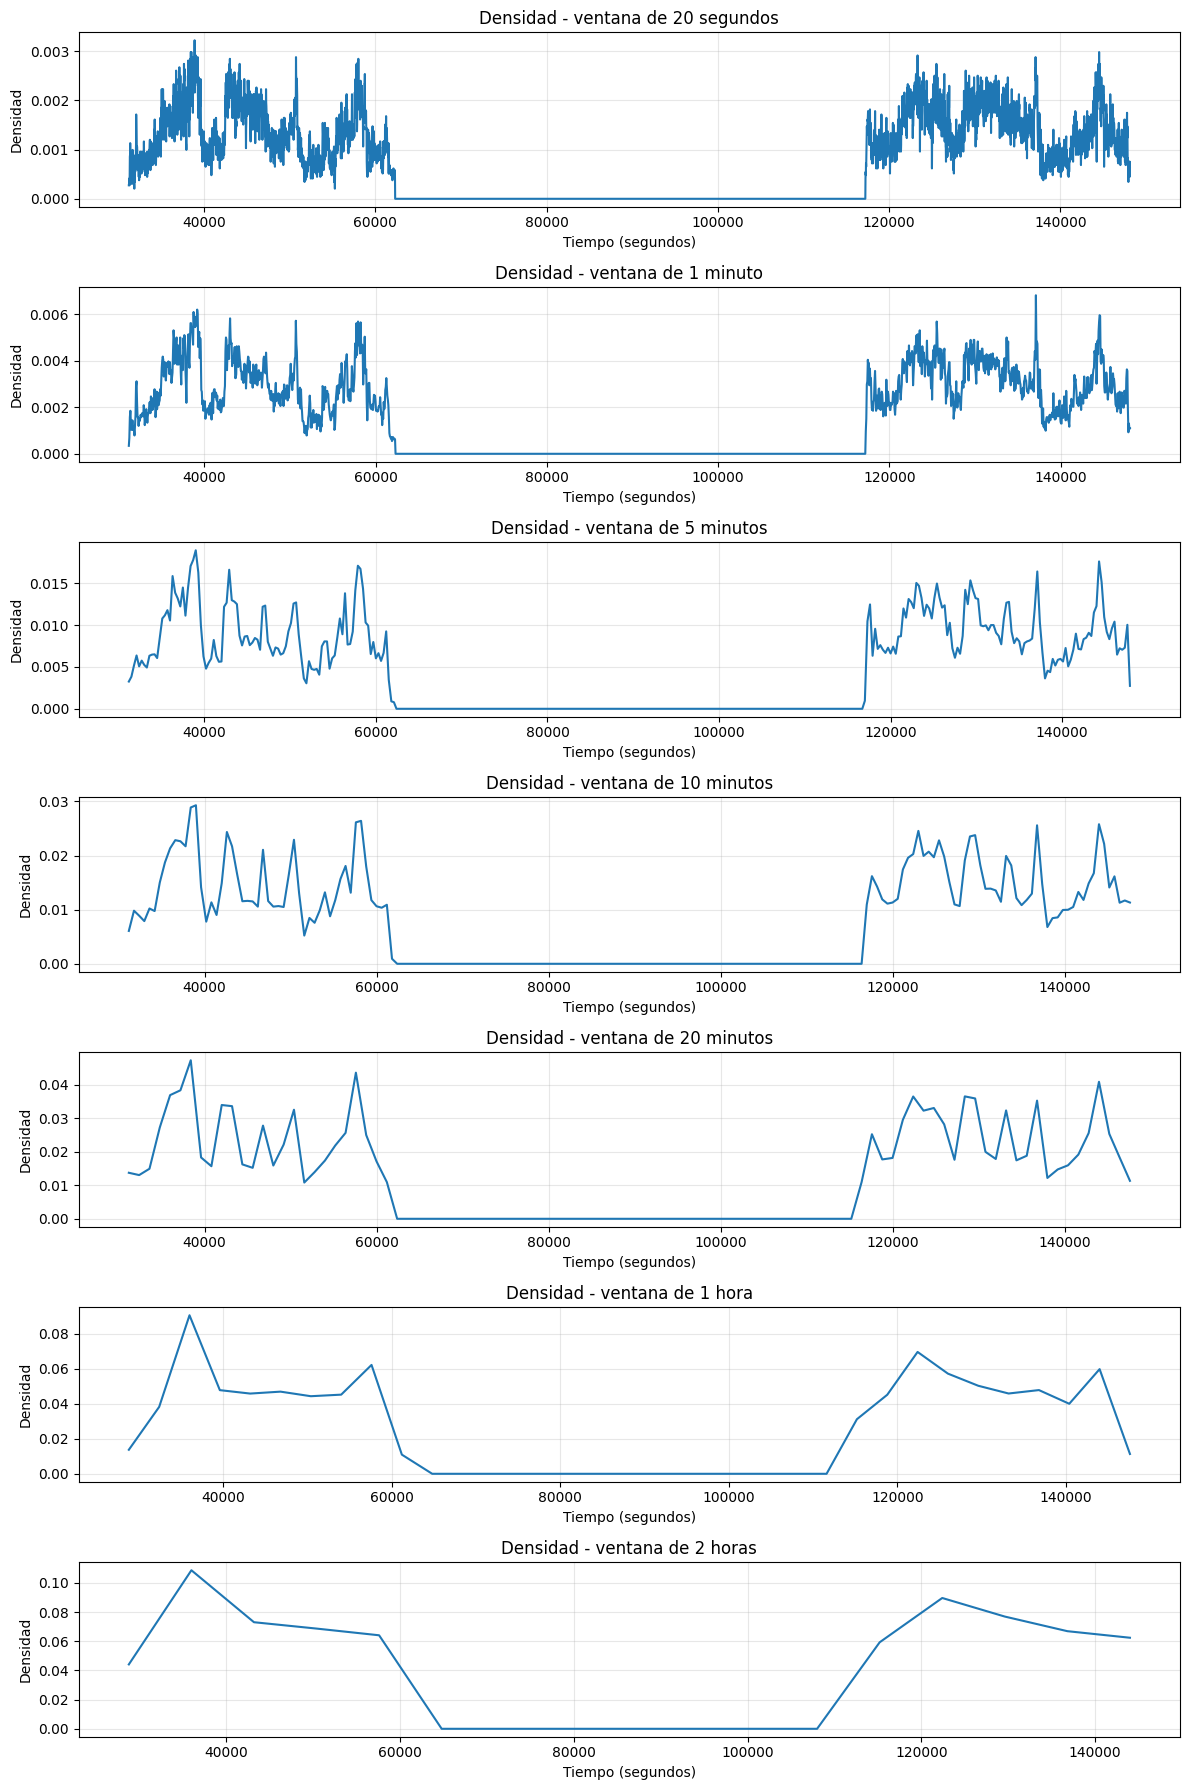

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURACIÓN
# ============================================================

N = len(nodos)

# Ventanas temporales en segundos
ventanas = {
    "20 segundos": 20,
    "1 minuto": 60,
    "5 minutos": 5 * 60,
    "10 minutos": 10 * 60,
    "20 minutos": 20 * 60,
    "1 hora": 60 * 60,
    "2 horas": 2 * 60 * 60,
}


# ============================================================
# FUNCIÓN PARA AGREGAR TEMPORALMENTE
# ============================================================

def analizar_ventana(df, ventana, N):

    datos = df.copy()

    # Asignar cada contacto a una ventana temporal
    datos["time_window"] = (
        datos["time"] // ventana
    ).astype(int)

    # Número de relaciones diferentes por ventana
    relaciones = (
        datos
        .groupby("time_window")
        .size()
    )

    # Eliminar duplicados i-j dentro de cada ventana
    relaciones_unicas = (
        datos[
            ["source", "target", "time_window"]
        ]
        .drop_duplicates()
        .groupby("time_window")
        .size()
    )

    # Nodos activos
    nodos_activos = (
        datos
        .groupby("time_window")
        .apply(
            lambda x: len(
                set(x["source"]) |
                set(x["target"])
            )
        )
    )

    # Todos los intervalos existentes
    t_min = datos["time_window"].min()
    t_max = datos["time_window"].max()

    ventanas_completas = np.arange(
        t_min,
        t_max + 1
    )

    # Rellenar ventanas sin contactos con cero
    relaciones_unicas = (
        relaciones_unicas
        .reindex(
            ventanas_completas,
            fill_value=0
        )
    )

    nodos_activos = (
        nodos_activos
        .reindex(
            ventanas_completas,
            fill_value=0
        )
    )

    # Densidad
    densidad = (
        relaciones_unicas /
        (N * (N - 1) / 2)
    )

    return {
        "ventanas": ventanas_completas,
        "relaciones": relaciones_unicas,
        "nodos_activos": nodos_activos,
        "densidad": densidad
    }

resultados = {}

for nombre, ventana in ventanas.items():

    resultados[nombre] = analizar_ventana(
        df,
        ventana,
        N
    )


fig, axes = plt.subplots(
    len(ventanas),
    1,
    figsize=(12, 18)
)

for ax, (nombre, resultado) in zip(
    axes,
    resultados.items()
):

    ax.plot(
        resultado["ventanas"] * ventanas[nombre],
        resultado["densidad"]
    )

    ax.set_title(
        f"Densidad - ventana de {nombre}"
    )

    ax.set_xlabel("Tiempo (segundos)")
    ax.set_ylabel("Densidad")

    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Network 8: Copenhagen Networks

The data represents the multi-layer temporal network which connects a population of more than 700 university students over a period of four weeks. The dataset was collected via smartphones as part of the Copenhagen Networks Study (https://www.nature.com/articles/s41597-019-0325-x).
We include the network of physical proximity among the participants (estimated via Bluetooth signal strength), the network of phone calls (start time, duration, no content), the network of text messages (time of message, no content), and information about Facebook friendships. Thus, we provide multiple types of communication networks expressed in a single, large population with high temporal resolution, and over a period of multiple weeks, a fact which makes the dataset shared here unique. 

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\data\copen_nets"

DATA_FILENAMES = {
    "bluetooth": "bt_symmetric.csv",
    "calls": "calls.csv",
    "sms": "sms.csv",
    "facebook_friends": "fb_friends.csv",
    "genders": "genders.csv"
}

def LoadData(data_filename, data_dir):
    """Loads data from data_dir/data_filename."""
    return pd.read_csv(os.path.join(data_dir, data_filename))


df_bt = LoadData(DATA_FILENAMES["bluetooth"], DATA_DIR)
df_calls = LoadData(DATA_FILENAMES["calls"], DATA_DIR)
df_sms = LoadData(DATA_FILENAMES["sms"], DATA_DIR)
df_facebook_friends = LoadData(DATA_FILENAMES["facebook_friends"], DATA_DIR)
df_genders = LoadData(DATA_FILENAMES["genders"], DATA_DIR)

df_bt = df_bt.rename(columns={"# timestamp": "timestamp"})
df_facebook_friends = df_facebook_friends.rename(
    columns={"# user_a": "user_a"}
)
df_genders = df_genders.rename(
    columns={"# user": "user"}
)

print("Bluetooth:")
display(df_bt.head())

print("Calls:")
display(df_calls.head())

print("SMS:")
display(df_sms.head())

print("Facebook:")
display(df_facebook_friends.head())

print("Genders:")
display(df_genders.head())



Bluetooth:


,timestamp,user_a,user_b,rssi
0,0,0,-1,0
1,0,1,-1,0
2,0,2,-1,0
3,0,3,-2,-88
4,0,5,-1,0


Calls:


,timestamp,caller,callee,duration
0,184,300,301,121
1,3920,512,299,670
2,5623,301,300,504
3,9252,401,457,-1
4,15466,512,0,5


SMS:


,timestamp,sender,recipient
0,18,370,512
1,37,512,370
2,126,370,512
3,134,0,512
4,312,137,136


Facebook:


,user_a,user_b
0,0,512
1,0,263
2,0,525
3,0,285
4,0,543


Genders:


,user,female
0,0,0
1,2,0
2,3,0
3,4,0
4,5,0


In [2]:
for name, df in {
    "Bluetooth": df_bt,
    "Calls": df_calls,
    "SMS": df_sms,
    "Facebook": df_facebook_friends,
    "Genders": df_genders
}.items():

    print("\n" + "="*50)
    print(name)
    print("Dimensiones:", df.shape)
    print("Columnas:", list(df.columns))
    print(df.head())


Bluetooth
Dimensiones: (5474289, 4)
Columnas: ['timestamp', 'user_a', 'user_b', 'rssi']
   timestamp  user_a  user_b  rssi
0          0       0      -1     0
1          0       1      -1     0
2          0       2      -1     0
3          0       3      -2   -88
4          0       5      -1     0

Calls
Dimensiones: (3600, 4)
Columnas: ['timestamp', 'caller', 'callee', 'duration']
   timestamp  caller  callee  duration
0        184     300     301       121
1       3920     512     299       670
2       5623     301     300       504
3       9252     401     457        -1
4      15466     512       0         5

SMS
Dimensiones: (24333, 3)
Columnas: ['timestamp', 'sender', 'recipient']
   timestamp  sender  recipient
0         18     370        512
1         37     512        370
2        126     370        512
3        134       0        512
4        312     137        136

Facebook
Dimensiones: (6429, 2)
Columnas: ['user_a', 'user_b']
   user_a  user_b
0       0     512
1       0    

In [3]:
# Bluetooth
bt = df_bt[["user_a", "user_b", "timestamp"]].copy()
bt["layer"] = "bluetooth"

# Calls
calls = df_calls[["caller", "callee", "timestamp"]].copy()
calls = calls.rename(columns={
    "caller": "source",
    "callee": "target"
})
calls["layer"] = "calls"

# SMS
sms = df_sms[["sender", "recipient", "timestamp"]].copy()
sms = sms.rename(columns={
    "sender": "source",
    "recipient": "target"
})
sms["layer"] = "sms"

bt = bt.rename(columns={
    "user_a": "source",
    "user_b": "target"
})

bt = df_bt[["user_a", "user_b", "timestamp"]].copy()

bt = bt.rename(columns={
    "user_a": "source",
    "user_b": "target"
})

bt["layer"] = "bluetooth"

dynamic_network = pd.concat(
    [bt, calls, sms],
    ignore_index=True
)

dynamic_network = dynamic_network.sort_values("timestamp")

display(dynamic_network)

,source,target,timestamp,layer
239,336,-1,0,bluetooth
177,245,-1,0,bluetooth
178,247,-2,0,bluetooth
179,248,-1,0,bluetooth
180,249,-2,0,bluetooth
...,...,...,...,...
5474247,658,-1,2418900,bluetooth
5474214,594,-2,2418900,bluetooth
5474245,656,-2,2418900,bluetooth
5474230,624,-1,2418900,bluetooth


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Limpieza de nombres de columnas
# ---------------------------------------------------------

df_bt = df_bt.rename(columns={"# timestamp": "timestamp"})
df_facebook_friends = df_facebook_friends.rename(
    columns={"# user_a": "user_a"}
)
df_genders = df_genders.rename(
    columns={"# user": "user"}
)

# ---------------------------------------------------------
# Información general
# ---------------------------------------------------------

datasets = {
    "Bluetooth": df_bt,
    "Calls": df_calls,
    "SMS": df_sms,
    "Facebook": df_facebook_friends,
    "Genders": df_genders
}

for name, df in datasets.items():
    print("\n" + "="*60)
    print(name)
    print("="*60)
    print("Dimensiones:", df.shape)
    print("Columnas:", list(df.columns))
    print("\nValores nulos:")
    print(df.isna().sum())


Bluetooth
Dimensiones: (5474289, 4)
Columnas: ['timestamp', 'user_a', 'user_b', 'rssi']

Valores nulos:
timestamp    0
user_a       0
user_b       0
rssi         0
dtype: int64

Calls
Dimensiones: (3600, 4)
Columnas: ['timestamp', 'caller', 'callee', 'duration']

Valores nulos:
timestamp    0
caller       0
callee       0
duration     0
dtype: int64

SMS
Dimensiones: (24333, 3)
Columnas: ['timestamp', 'sender', 'recipient']

Valores nulos:
timestamp    0
sender       0
recipient    0
dtype: int64

Facebook
Dimensiones: (6429, 2)
Columnas: ['user_a', 'user_b']

Valores nulos:
user_a    0
user_b    0
dtype: int64

Genders
Dimensiones: (787, 2)
Columnas: ['user', 'female']

Valores nulos:
user      0
female    0
dtype: int64


In [5]:
nodes_bt = set(df_bt["user_a"]) | set(df_bt["user_b"])

nodes_calls = set(df_calls["caller"]) | set(df_calls["callee"])

nodes_sms = set(df_sms["sender"]) | set(df_sms["recipient"])

nodes_fb = set(
    df_facebook_friends["user_a"]
) | set(
    df_facebook_friends["user_b"]
)

print("Bluetooth:", len(nodes_bt))
print("Calls:", len(nodes_calls))
print("SMS:", len(nodes_sms))
print("Facebook:", len(nodes_fb))
print("Genders:", df_genders["user"].nunique())

Bluetooth: 708
Calls: 536
SMS: 568
Facebook: 800
Genders: 787


In [10]:
for name, df in datasets.items():
    print(f"{name:15s}: {len(df):,} registros")


bt_pairs = df_bt[["user_a", "user_b"]].drop_duplicates()

print("Bluetooth")
print("Eventos:", len(df_bt))
print("Pares únicos:", len(bt_pairs))

call_pairs = df_calls[["caller", "callee"]].drop_duplicates()

print("Calls")
print("Eventos:", len(df_calls))
print("Pares únicos:", len(call_pairs))

sms_pairs = df_sms[["sender", "recipient"]].drop_duplicates()

print("SMS")
print("Eventos:", len(df_sms))
print("Pares únicos:", len(sms_pairs))

fb_pairs = df_facebook_friends[["user_a", "user_b"]].drop_duplicates()

print("Facebook")
print("Relaciones:", len(df_facebook_friends))
print("Pares únicos:", len(fb_pairs))

Bluetooth      : 5,474,289 registros
Calls          : 3,600 registros
SMS            : 24,333 registros
Facebook       : 6,429 registros
Genders        : 787 registros
Bluetooth
Eventos: 5474289
Pares únicos: 80886
Calls
Eventos: 3600
Pares únicos: 924
SMS
Eventos: 24333
Pares únicos: 1303
Facebook
Relaciones: 6429
Pares únicos: 6429


Bluetooth:
0 2418900

Calls:
184 2416399

SMS:
18 2418982


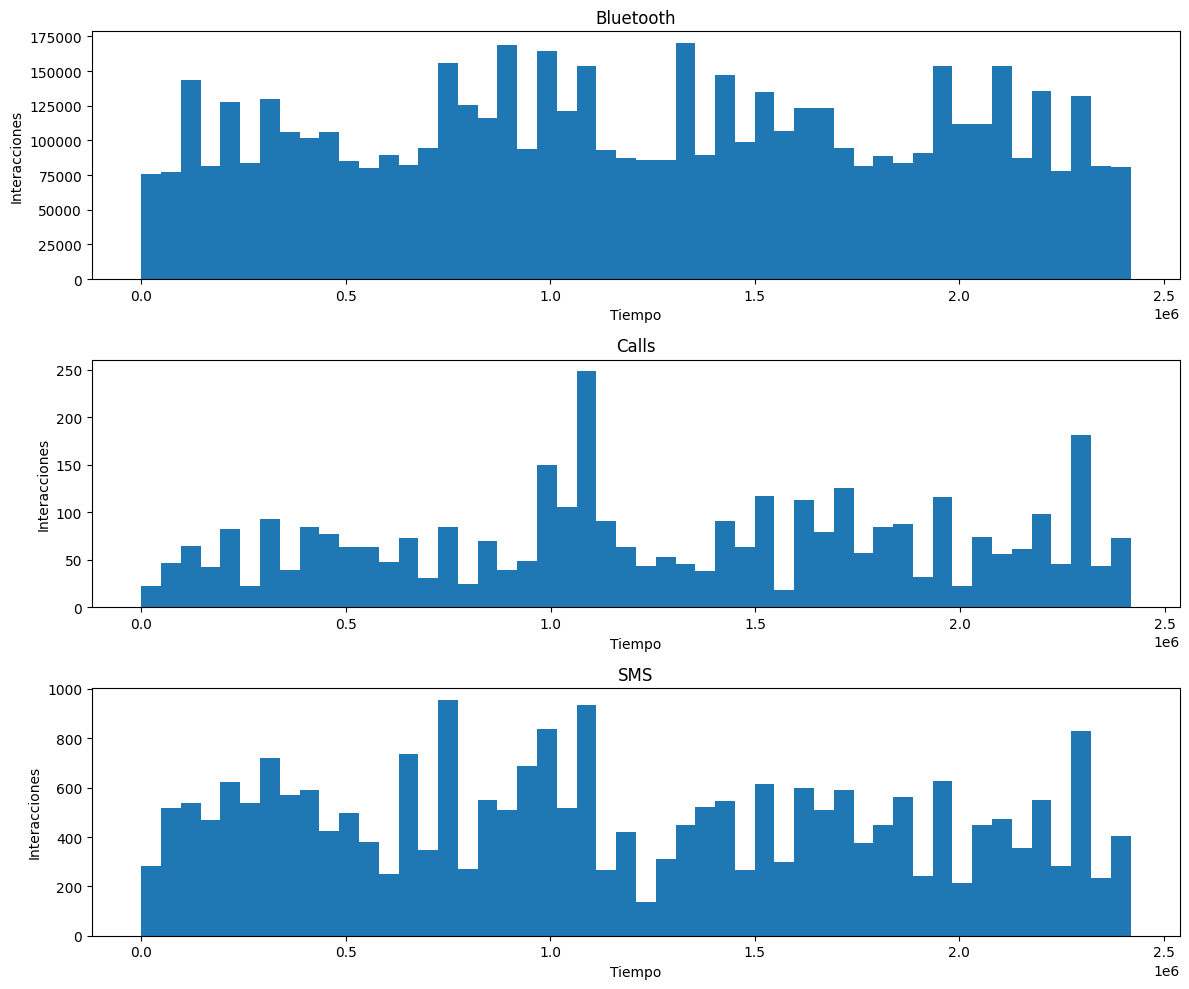

In [12]:
print("Bluetooth:")
print(df_bt["timestamp"].min(), df_bt["timestamp"].max())

print("\nCalls:")
print(df_calls["timestamp"].min(), df_calls["timestamp"].max())

print("\nSMS:")
print(df_sms["timestamp"].min(), df_sms["timestamp"].max())

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].hist(df_bt["timestamp"], bins=50)
axes[0].set_title("Bluetooth")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Interacciones")

axes[1].hist(df_calls["timestamp"], bins=50)
axes[1].set_title("Calls")
axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Interacciones")

axes[2].hist(df_sms["timestamp"], bins=50)
axes[2].set_title("SMS")
axes[2].set_xlabel("Tiempo")
axes[2].set_ylabel("Interacciones")

plt.tight_layout()
plt.show()

In [13]:
# ¿Cuántos pares aparecen en ambas direcciones?

calls_forward = set(
    zip(df_calls["caller"], df_calls["callee"])
)

calls_reverse = set(
    (j, i) for i, j in calls_forward
)

mutual_calls = calls_forward.intersection(calls_reverse)

print("Pares dirigidos:", len(calls_forward))
print("Pares con interacción en ambas direcciones:", len(mutual_calls))

Pares dirigidos: 924
Pares con interacción en ambas direcciones: 606


In [14]:
sms_forward = set(
    zip(df_sms["sender"], df_sms["recipient"])
)

sms_reverse = set(
    (j, i) for i, j in sms_forward
)

mutual_sms = sms_forward.intersection(sms_reverse)

print("Pares dirigidos:", len(sms_forward))
print("Pares con interacción en ambas direcciones:", len(mutual_sms))

Pares dirigidos: 1303
Pares con interacción en ambas direcciones: 1212


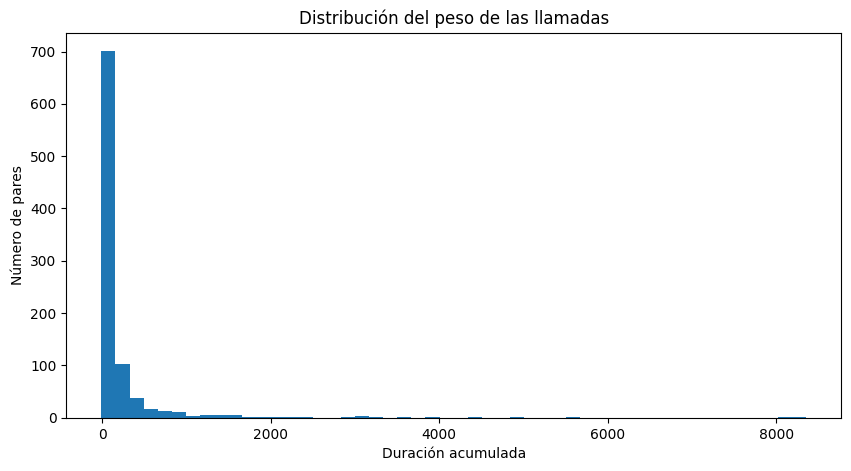

In [19]:
call_weights = (
    df_calls
    .groupby(["caller", "callee"])["duration"]
    .sum()
    .reset_index()
)

call_weights.head()

plt.figure(figsize=(10, 5))

plt.hist(
    call_weights["duration"],
    bins=50
)

plt.xlabel("Duración acumulada")
plt.ylabel("Número de pares")
plt.title("Distribución del peso de las llamadas")
plt.show()

In [20]:
sms_weights = (
    df_sms
    .groupby(["sender", "recipient"])
    .size()
    .reset_index(name="weight")
)

sms_weights.head()

,sender,recipient,weight
0,0,208,1
1,0,512,61
2,1,345,2
3,3,49,41
4,3,217,3


count    5.474289e+06
mean    -4.994969e+01
std      4.207211e+01
min     -1.070000e+02
25%     -8.800000e+01
50%     -7.400000e+01
75%      0.000000e+00
max      2.000000e+01
Name: rssi, dtype: float64

Valores de RSSI:
rssi
 0     2220136
-92     181226
-90     179679
-86     150017
-94     147075
-88     134427
-93     134404
-95     132678
-87     118153
-96     115323
-84     111180
-82     104553
-91     104397
-83      96711
-80      95009
-81      90054
-97      88891
-75      87772
-85      85322
-78      80192
Name: count, dtype: int64


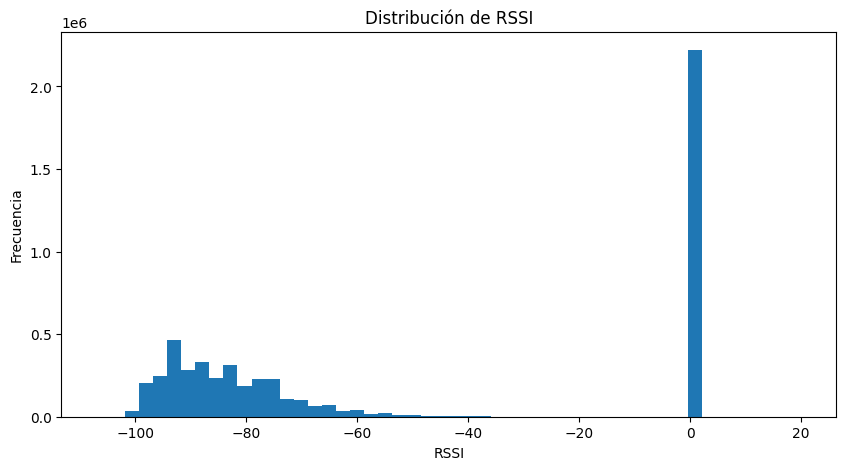

In [21]:
print(df_bt["rssi"].describe())

print("\nValores de RSSI:")
print(df_bt["rssi"].value_counts().head(20))

plt.figure(figsize=(10, 5))

plt.hist(
    df_bt["rssi"],
    bins=50
)

plt.xlabel("RSSI")
plt.ylabel("Frecuencia")
plt.title("Distribución de RSSI")

plt.show()

In [23]:
print("BT ∩ Calls:",
      len(nodes_bt & nodes_calls))

print("BT ∩ SMS:",
      len(nodes_bt & nodes_sms))

print("BT ∩ Facebook:",
      len(nodes_bt & nodes_fb))

print("Calls ∩ SMS:",
      len(nodes_calls & nodes_sms))

print("Calls ∩ Facebook:",
      len(nodes_calls & nodes_fb))

print("SMS ∩ Facebook:",
      len(nodes_sms & nodes_fb))


common_nodes = (
    nodes_bt
    & nodes_calls
    & nodes_sms
    & nodes_fb
)

print("Nodos presentes en las 4 capas:", len(common_nodes))

BT ∩ Calls: 498
BT ∩ SMS: 531
BT ∩ Facebook: 670
Calls ∩ SMS: 496
Calls ∩ Facebook: 505
SMS ∩ Facebook: 538
Nodos presentes en las 4 capas: 440


In [24]:
def undirected_pairs(df, col1, col2):
    return {
        tuple(sorted((a, b)))
        for a, b in zip(df[col1], df[col2])
        if a != b
    }

bt_pairs = undirected_pairs(df_bt, "user_a", "user_b")

fb_pairs = undirected_pairs(
    df_facebook_friends,
    "user_a",
    "user_b"
)

In [25]:
call_pairs_undirected = undirected_pairs(
    df_calls,
    "caller",
    "callee"
)

sms_pairs_undirected = undirected_pairs(
    df_sms,
    "sender",
    "recipient"
)

In [26]:
layers = {
    "Bluetooth": bt_pairs,
    "Calls": call_pairs_undirected,
    "SMS": sms_pairs_undirected,
    "Facebook": fb_pairs
}

for name1, pairs1 in layers.items():
    for name2, pairs2 in layers.items():
        if name1 < name2:
            intersection = pairs1 & pairs2

            print(
                f"{name1} ∩ {name2}: "
                f"{len(intersection):,}"
            )

Bluetooth ∩ Calls: 515
Bluetooth ∩ SMS: 572
Bluetooth ∩ Facebook: 3,133
Calls ∩ SMS: 438
Calls ∩ Facebook: 503
Facebook ∩ SMS: 576
